In [15]:

import pandas as pd
run_to_plot_file = 'data/runs_to_plot.csv'
df = pd.read_csv(run_to_plot_file)

# from the dataframe get the path to the bag file
base_path = '/home/user/applr_ws/src/Results/test'

# get the path to the bag file
from pathlib import Path
import os
def get_bag_path(row, base_path):
    if 'SFW' in row['method']:
        bag_prefix = 'DumbNav'
        if 'SAC' in row['method']:
            bag_prefix = 'SFW/SAC'
    else:
        bag_prefix = 'SFW/SAC'
    model_path = base_path + '/' + bag_prefix + '/' + row['method'] + '/' + row['experiment']
    model_path = Path(model_path)
    bag_path = os.path.join(model_path, os.listdir(model_path)[-1], 'bags', f'episode_{row["episode"]}',f'episode_{row["episode"]}_0.db3')
    return bag_path

df['bag_path'] = df.apply(lambda row: get_bag_path(row, base_path), axis=1)

df

,method,episode,experiment,environment,outcome,bag_path
0,SFW_base,0,social_nav,1,Goal,/home/user/applr_ws/src/Results/test/DumbNav/S...
1,SFW,0,social_nav,1,Goal,/home/user/applr_ws/src/Results/test/DumbNav/S...
2,SFW_SAC_160k,0,social_nav,1,Goal,/home/user/applr_ws/src/Results/test/SFW/SAC/S...
3,SFW_base,22,social_nav,2,Goal,/home/user/applr_ws/src/Results/test/DumbNav/S...
4,SFW,2,social_nav,2,Goal,/home/user/applr_ws/src/Results/test/DumbNav/S...
5,SFW_SAC_160k,2,social_nav,2,Goal,/home/user/applr_ws/src/Results/test/SFW/SAC/S...
6,SFW_base,3,social_nav,3,Collision,/home/user/applr_ws/src/Results/test/DumbNav/S...
7,SFW,3,social_nav,3,Collision,/home/user/applr_ws/src/Results/test/DumbNav/S...
8,SFW_SAC_160k,13,social_nav,3,Goal,/home/user/applr_ws/src/Results/test/SFW/SAC/S...
9,SFW_base,55,social_nav,4,Goal,/home/user/applr_ws/src/Results/test/DumbNav/S...


In [16]:
from rclpy.serialization import deserialize_message
from rosidl_runtime_py.utilities import get_message
from tf_transformations import euler_from_quaternion

from people_msgs.msg import People
from nav_msgs.msg import Odometry

import rosbag2_py
import numpy as np

output_folder = 'bags'
os.makedirs(output_folder, exist_ok=True)


def get_rosbag_options(path, serialization_format="cdr"):
    storage_options = rosbag2_py.StorageOptions(uri=path, storage_id="sqlite3")

    converter_options = rosbag2_py.ConverterOptions(
        input_serialization_format=serialization_format,
        output_serialization_format=serialization_format,
    )

    return storage_options, converter_options

for i, row in df.iterrows():
    # if i > 0:
    #     break
    print(row['bag_path'])
    storage_options, converter_options = get_rosbag_options(row['bag_path'])
    reader = rosbag2_py.SequentialReader()
    reader.open(storage_options, converter_options)

    topic_types = reader.get_all_topics_and_types()
    type_map = {topic_types[i].name: topic_types[i].type for i in range(len(topic_types))}

    storage_filter = rosbag2_py.StorageFilter(
        topics=[
            '/jackal/odom',
            '/people',
        ]
    )
    reader.set_filter(storage_filter)

    msgs = []
    while reader.has_next():
        (topic, data, t) = reader.read_next()
        msg_type = get_message(type_map[topic])
        msg = deserialize_message(data, msg_type)
        time = t / 1e9
        if msg_type is People:
            people = {}
            people['time'] = time 
            for i, person in enumerate(msg.people):
                people[f'person_{i}/x'] = person.position.x
                people[f'person_{i}/y'] = person.position.y
                people[f'person_{i}/yaw'] = person.position.z
            data = pd.Series(people)     

        if msg_type is Odometry:
            _, _, yaw = euler_from_quaternion(
                [
                    msg.pose.pose.orientation.x,
                    msg.pose.pose.orientation.y,
                    msg.pose.pose.orientation.z,
                    msg.pose.pose.orientation.w,
                ]
            )
            odom = {
                'time': time,
                'jackal/x': msg.pose.pose.position.x,
                'jackal/y': msg.pose.pose.position.y,
                'jackal/yaw': yaw,
            }
            data = pd.Series(odom)
        msgs.append(data)
    # df_1 = pd.DataFrame(msgs)
    output_path = os.path.join(output_folder, row['method'], f'env_{int(row["environment"])}.csv')
    if not os.path.exists(os.path.dirname(output_path)):
        os.makedirs(os.path.dirname(output_path))
    pd.DataFrame(msgs).to_csv(output_path, index=False)
    

/home/user/applr_ws/src/Results/test/DumbNav/SFW_base/social_nav/20240309_224247.602813_applr_SAC/bags/episode_0/episode_0_0.db3


[INFO] [1710531401.543253408] [rosbag2_storage]: Opened database '/home/user/applr_ws/src/Results/test/DumbNav/SFW_base/social_nav/20240309_224247.602813_applr_SAC/bags/episode_0/episode_0_0.db3' for READ_ONLY.


/home/user/applr_ws/src/Results/test/DumbNav/SFW/social_nav/20240309_174855.043736_applr_SAC/bags/episode_0/episode_0_0.db3


[INFO] [1710531402.256725622] [rosbag2_storage]: Opened database '/home/user/applr_ws/src/Results/test/DumbNav/SFW/social_nav/20240309_174855.043736_applr_SAC/bags/episode_0/episode_0_0.db3' for READ_ONLY.


/home/user/applr_ws/src/Results/test/SFW/SAC/SFW_SAC_160k/social_nav/20240308_181643.802957_applr_SAC/bags/episode_0/episode_0_0.db3


[INFO] [1710531402.834723102] [rosbag2_storage]: Opened database '/home/user/applr_ws/src/Results/test/SFW/SAC/SFW_SAC_160k/social_nav/20240308_181643.802957_applr_SAC/bags/episode_0/episode_0_0.db3' for READ_ONLY.


... (60 outputs left out)

/home/user/applr_ws/src/Results/test/DumbNav/SFW/social_env7/20240315_030638.479126_applr_SAC/bags/episode_1/episode_1_0.db3


[INFO] [1710531434.129530532] [rosbag2_storage]: Opened database '/home/user/applr_ws/src/Results/test/DumbNav/SFW/social_env7/20240315_030638.479126_applr_SAC/bags/episode_1/episode_1_0.db3' for READ_ONLY.


/home/user/applr_ws/src/Results/test/SFW/SAC/SFW_SAC_160k/social_env7/20240315_021622.578966_applr_SAC/bags/episode_1/episode_1_0.db3


[INFO] [1710531437.250782479] [rosbag2_storage]: Opened database '/home/user/applr_ws/src/Results/test/SFW/SAC/SFW_SAC_160k/social_env7/20240315_021622.578966_applr_SAC/bags/episode_1/episode_1_0.db3' for READ_ONLY.


In [17]:
import json

social_env_goals = '/home/user/applr_ws/src/APPLR_social_nav/applr_social_nav/goals_and_poses/social_env_test.json'
social_nav_goals = '/home/user/applr_ws/src/APPLR_social_nav/applr_social_nav/goals_and_poses/social_nav_test.json'
social_env7_goals = '/home/user/applr_ws/src/APPLR_social_nav/applr_social_nav/goals_and_poses/social_env7_test.json'

social_env_goals = json.load(open(social_env_goals))
social_nav_goals = json.load(open(social_nav_goals))
social_env7_goals = json.load(open(social_env7_goals))

social_env_goals = pd.DataFrame(social_env_goals['goals'], columns=['x', 'y'])
social_nav_goals = pd.DataFrame(social_nav_goals['goals'], columns=['x', 'y'])
social_env7_goals = pd.DataFrame(social_env7_goals['goals'], columns=['x', 'y'])

social_nav_episodes = [1, 3, 4, 6, 7, 9]
social_env_episodes = [2,3,4,8]
social_env7_episodes = [1,2]
goals = []
for i in social_nav_episodes:
    goals.append(social_nav_goals.iloc[i-1])
for i in social_env_episodes:
    goals.append(social_env_goals.iloc[i-1])
for i in social_env7_episodes:
    goals.append(social_env7_goals.iloc[i-1])

for i in range(0, len(goals)):
    goals[i]['environment'] = int(i+1)
goals = pd.DataFrame(goals)  
goals.reset_index(drop=True, inplace=True)


/tmp/ipykernel_2616581/3456685296.py:76: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  jackal_trajectory.rename(columns={'jackal/x':'x', 'jackal/y':'y', 'jackal/yaw':'yaw'}, inplace=True)
/tmp/ipykernel_2616581/3456685296.py:77: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  jackal_trajectory.interpolate(inplace=True)
/tmp/ipykernel_2616581/3456685296.py:146: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  person_trajectory.rename(columns

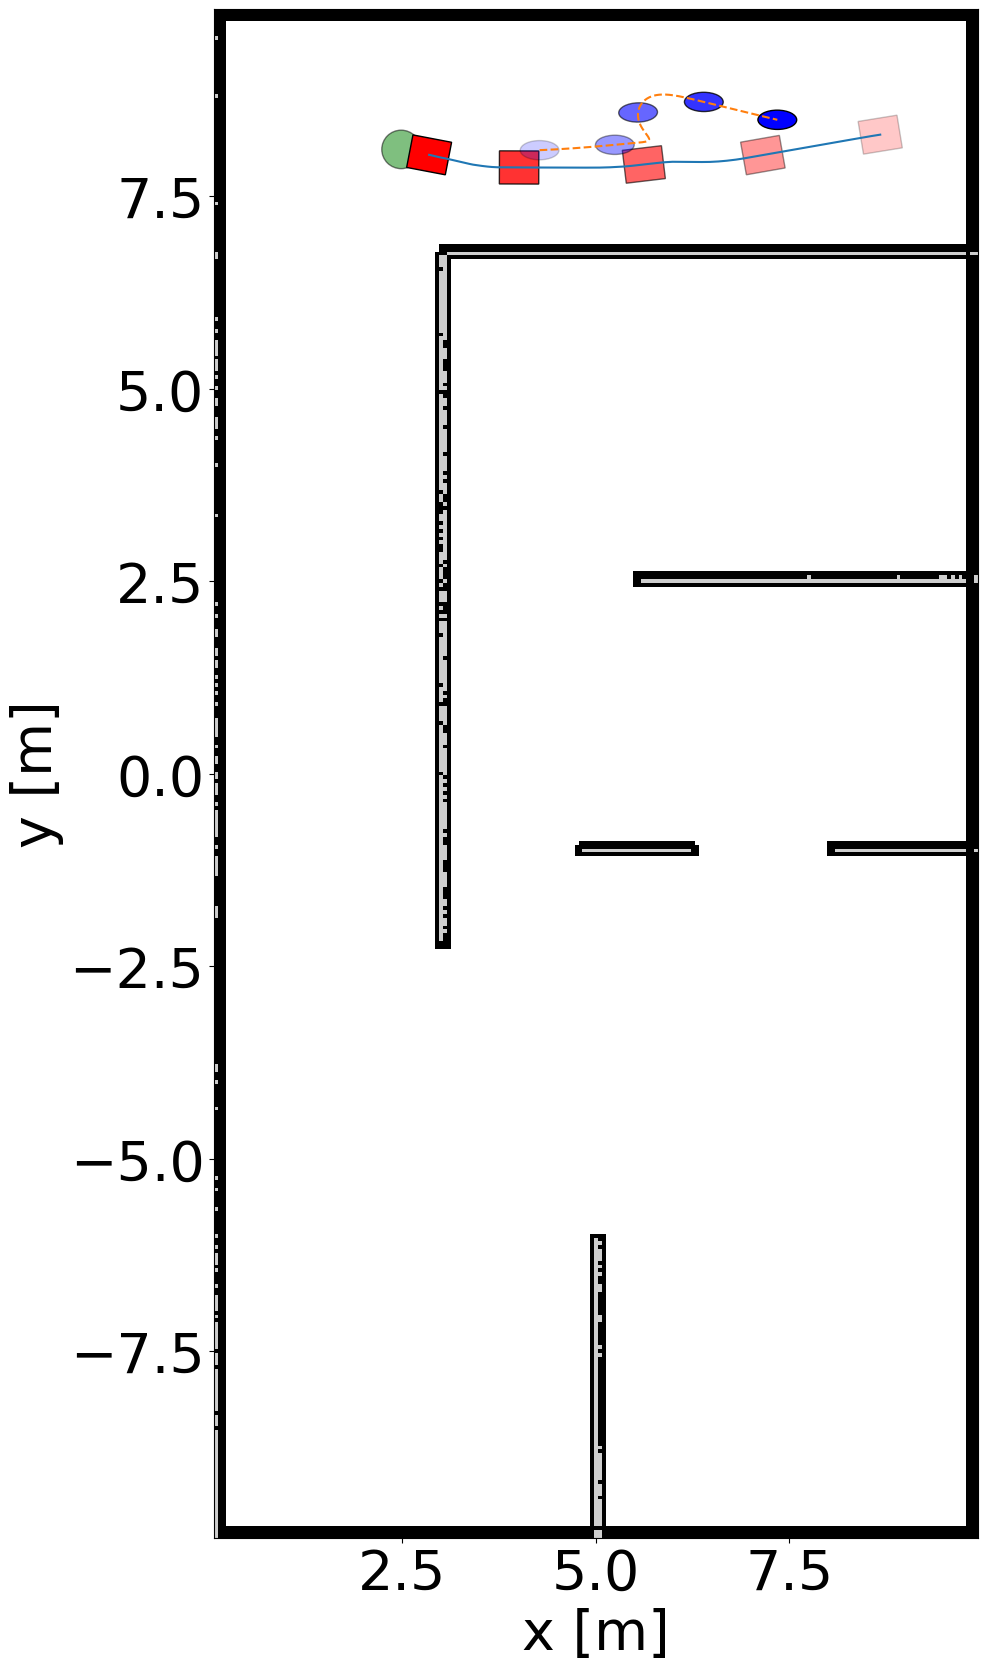

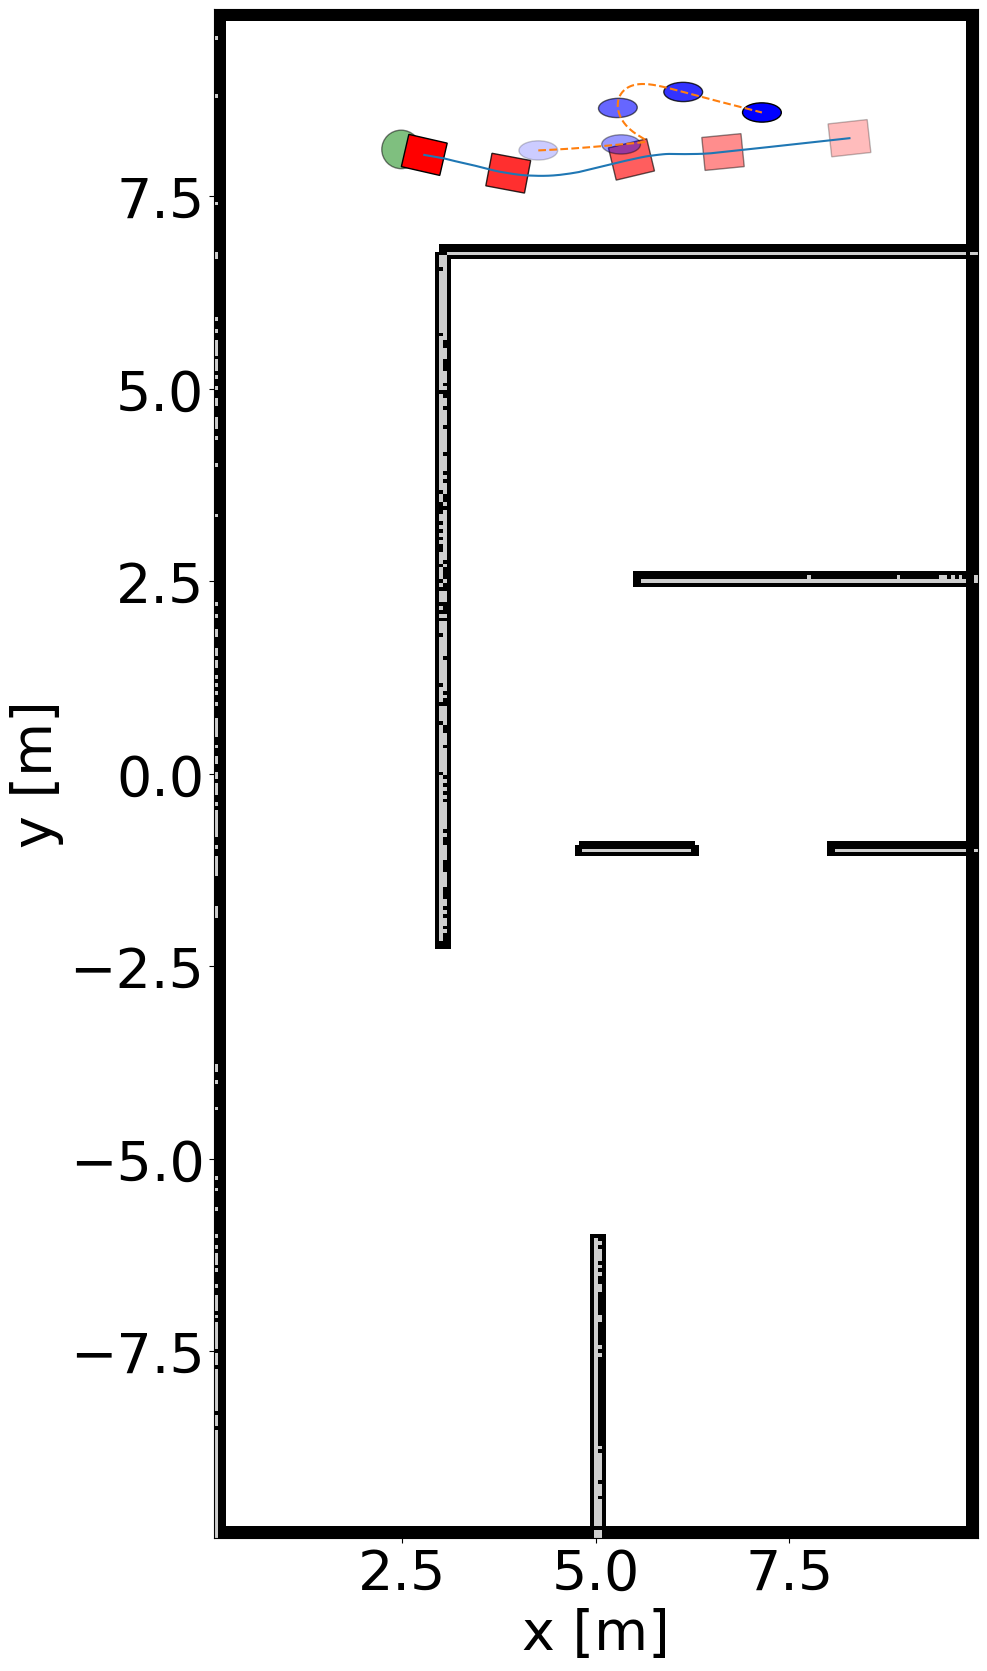

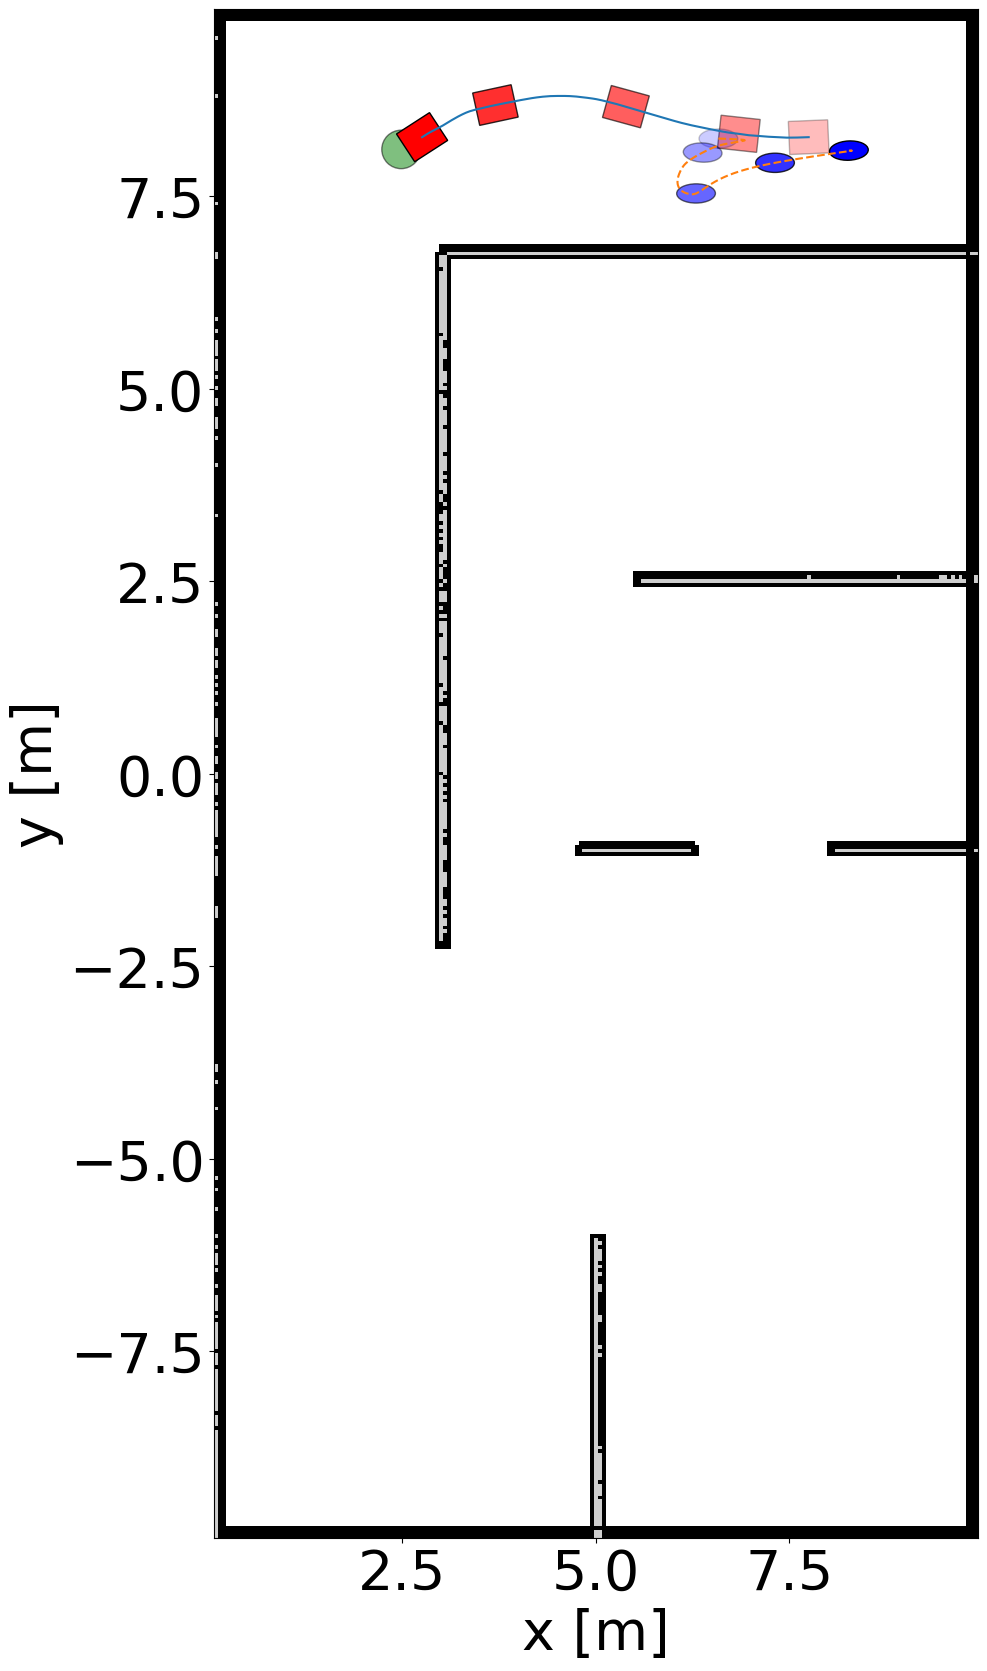

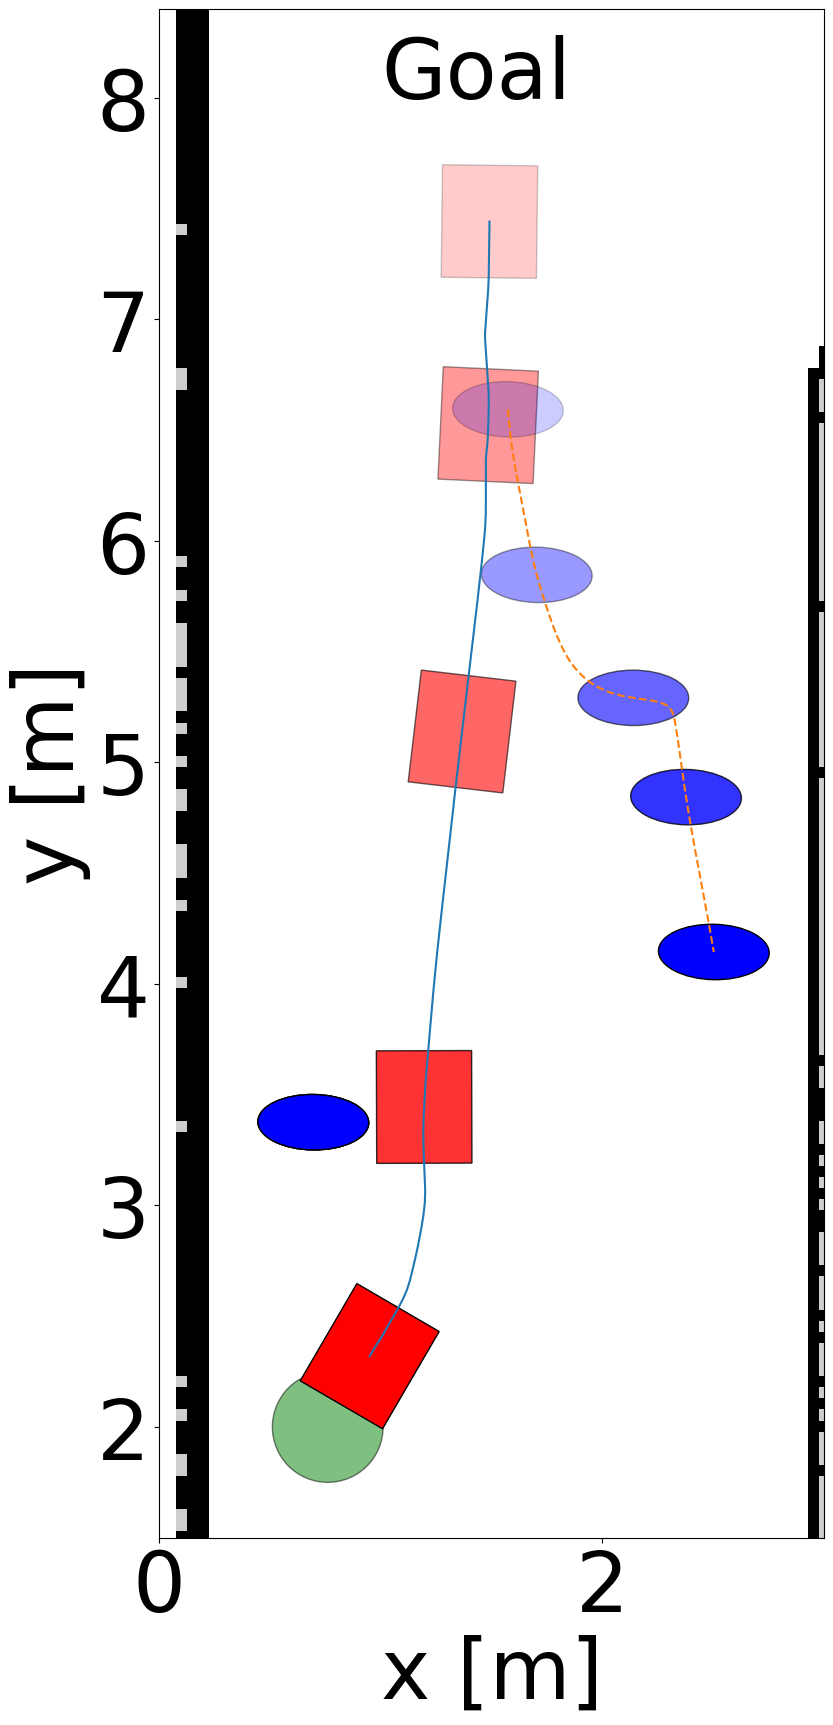

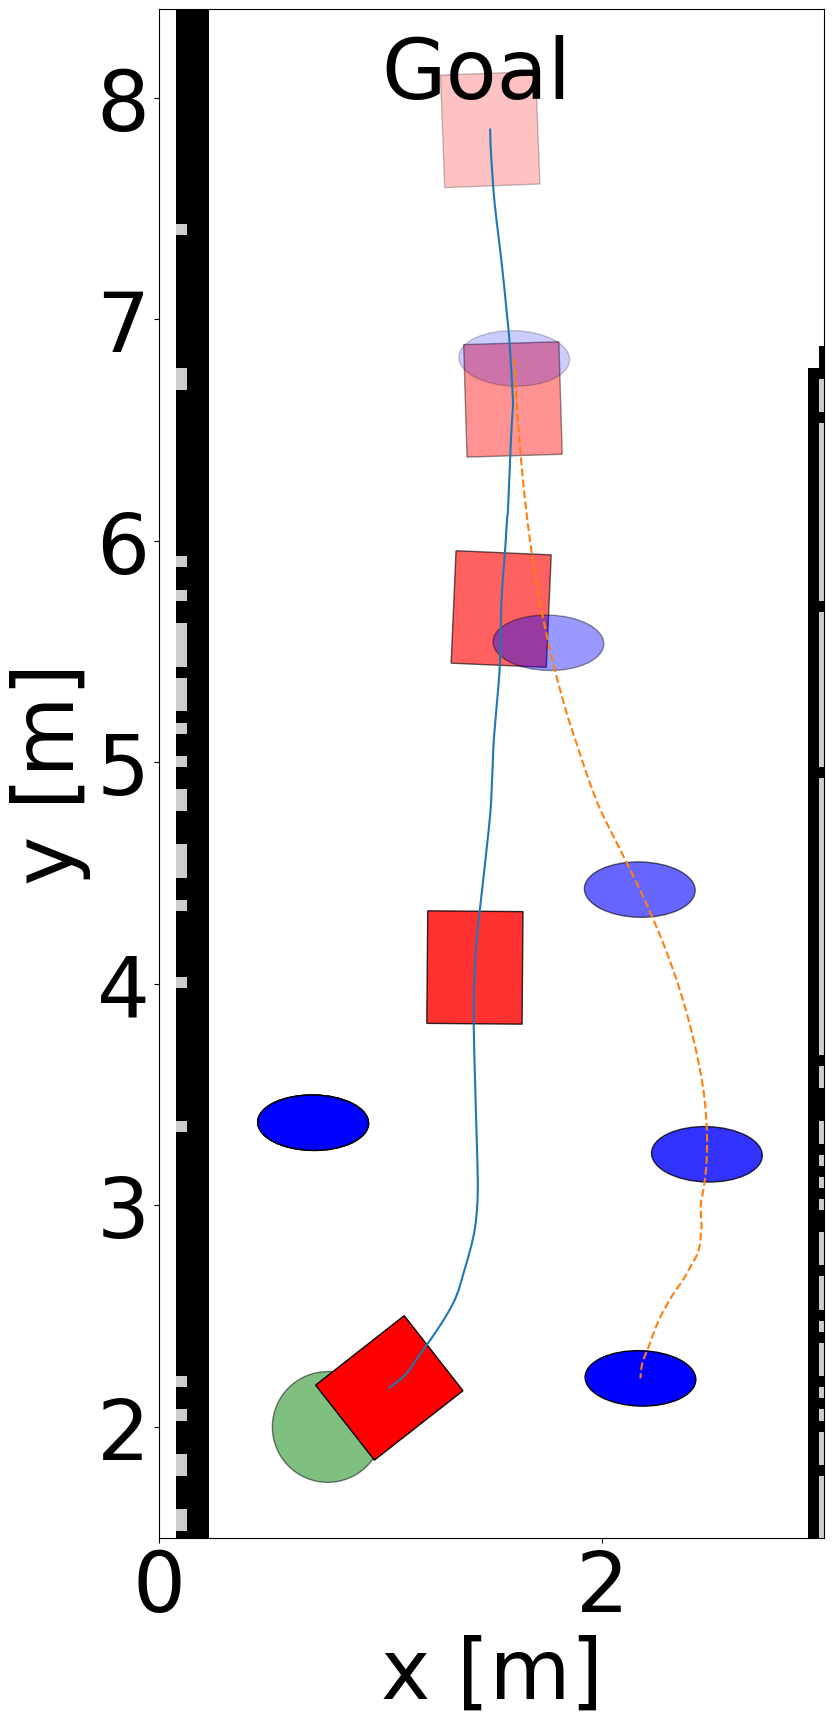

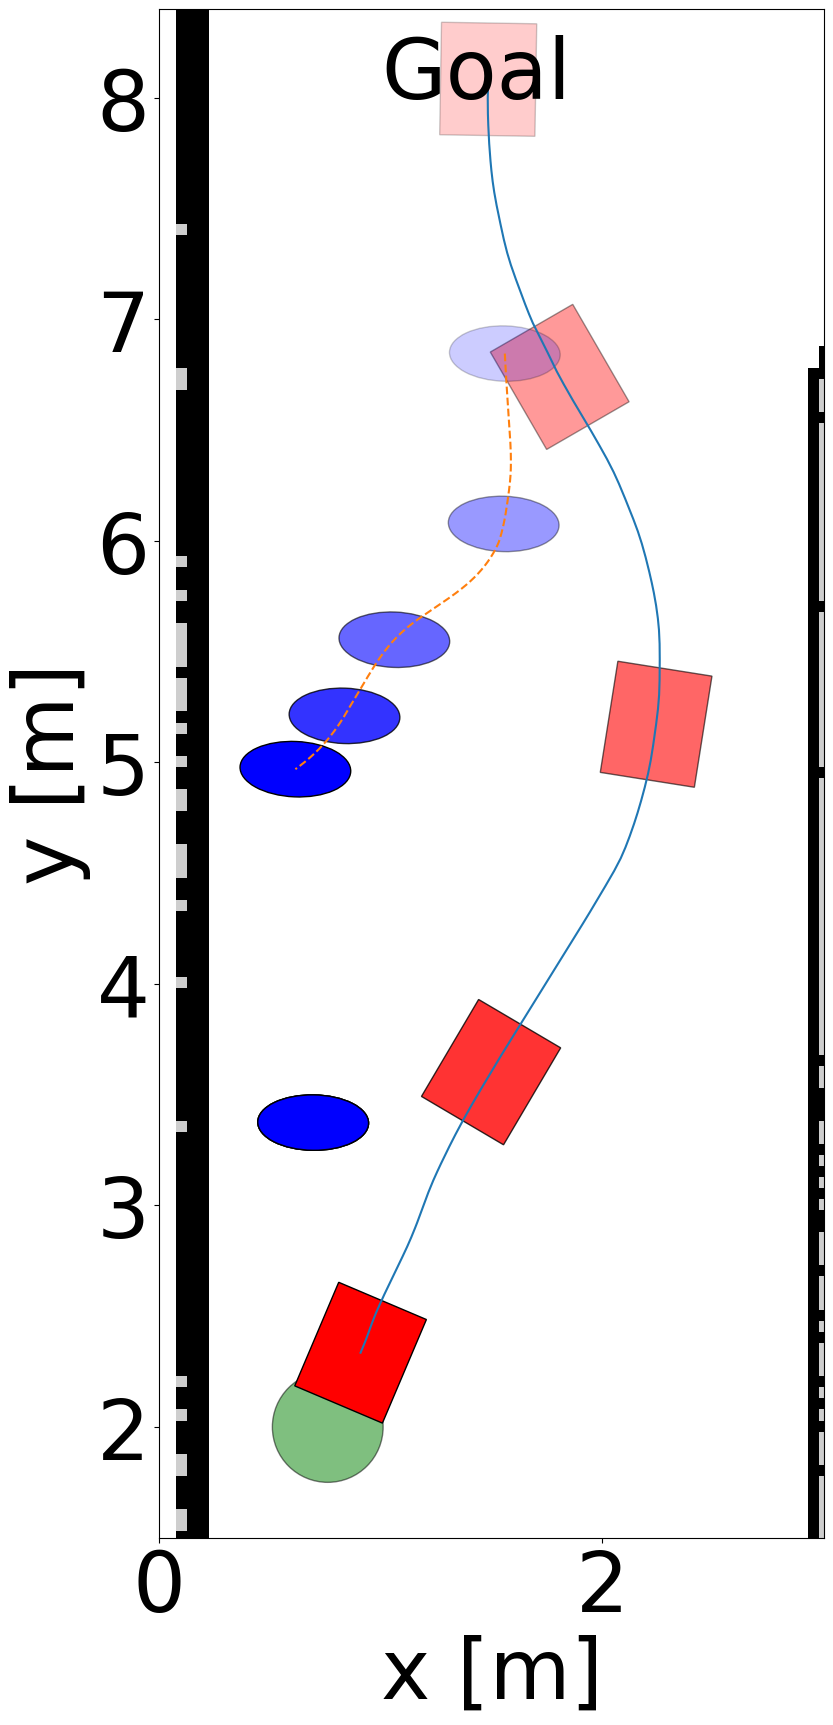

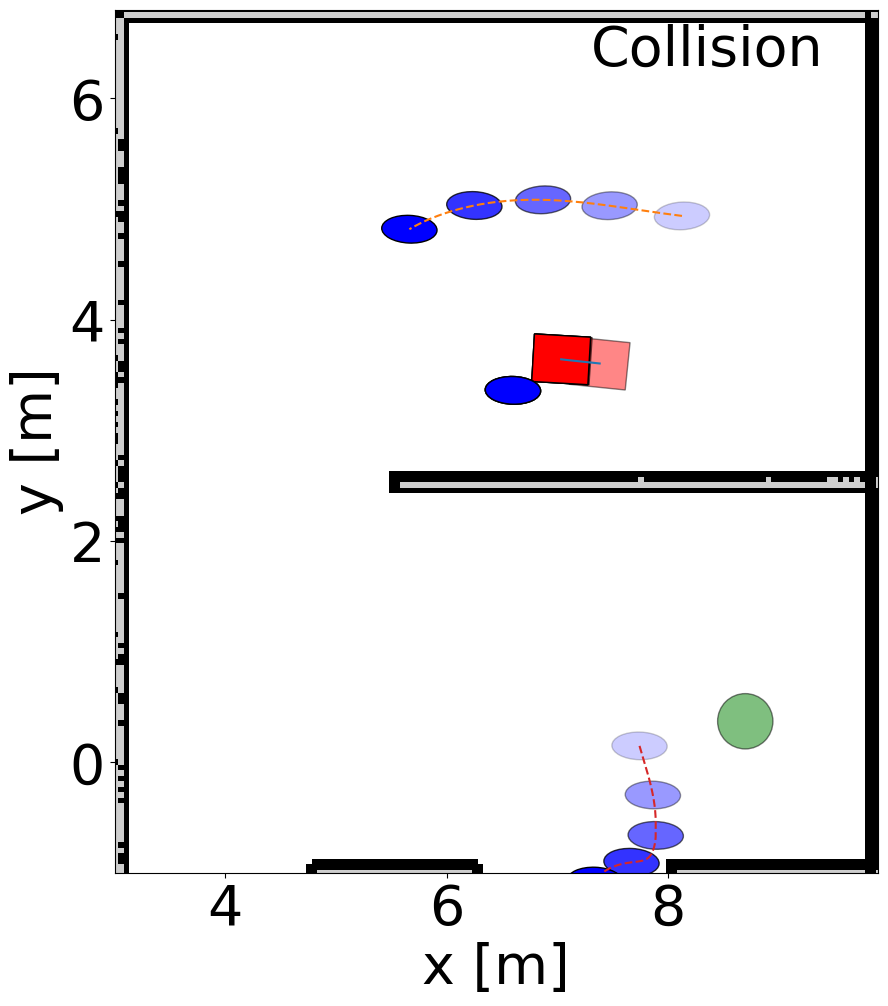

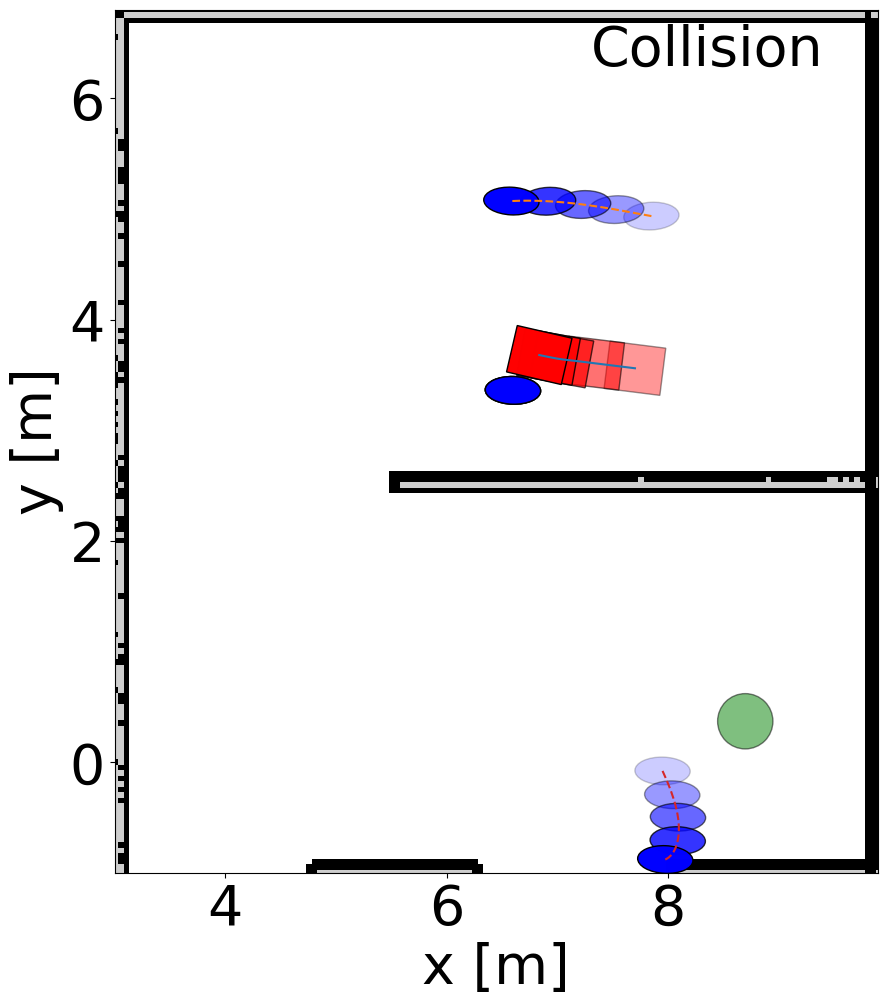

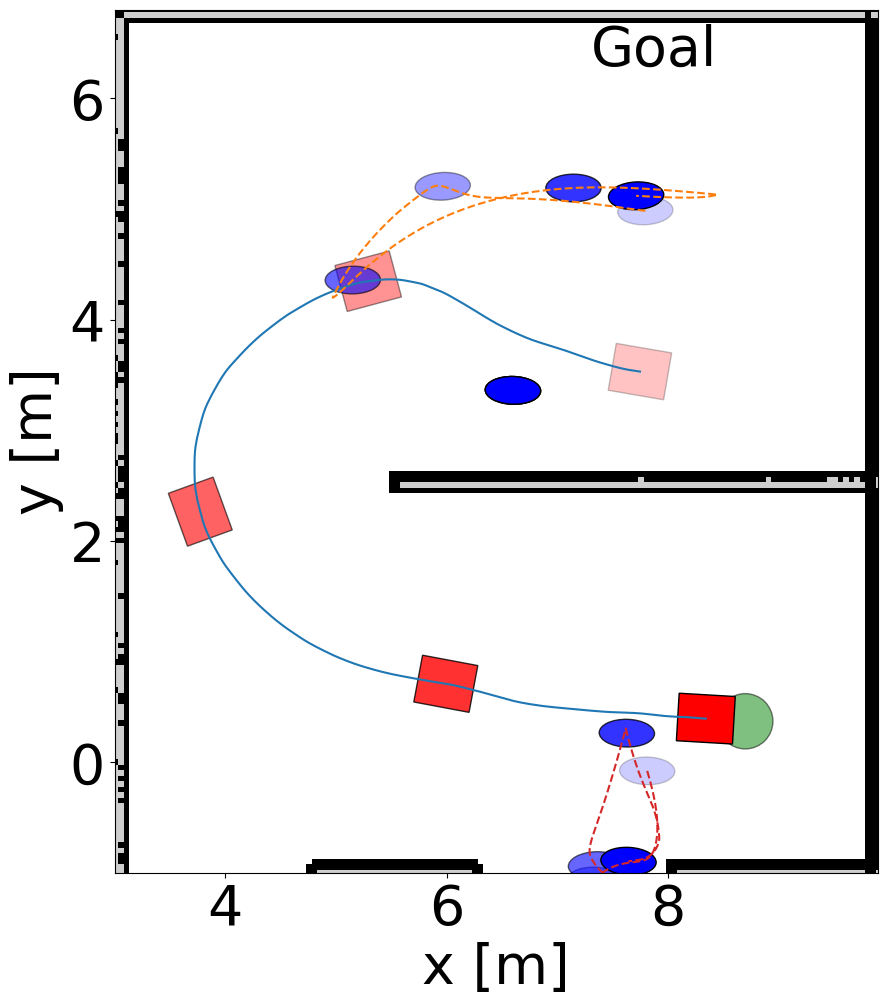

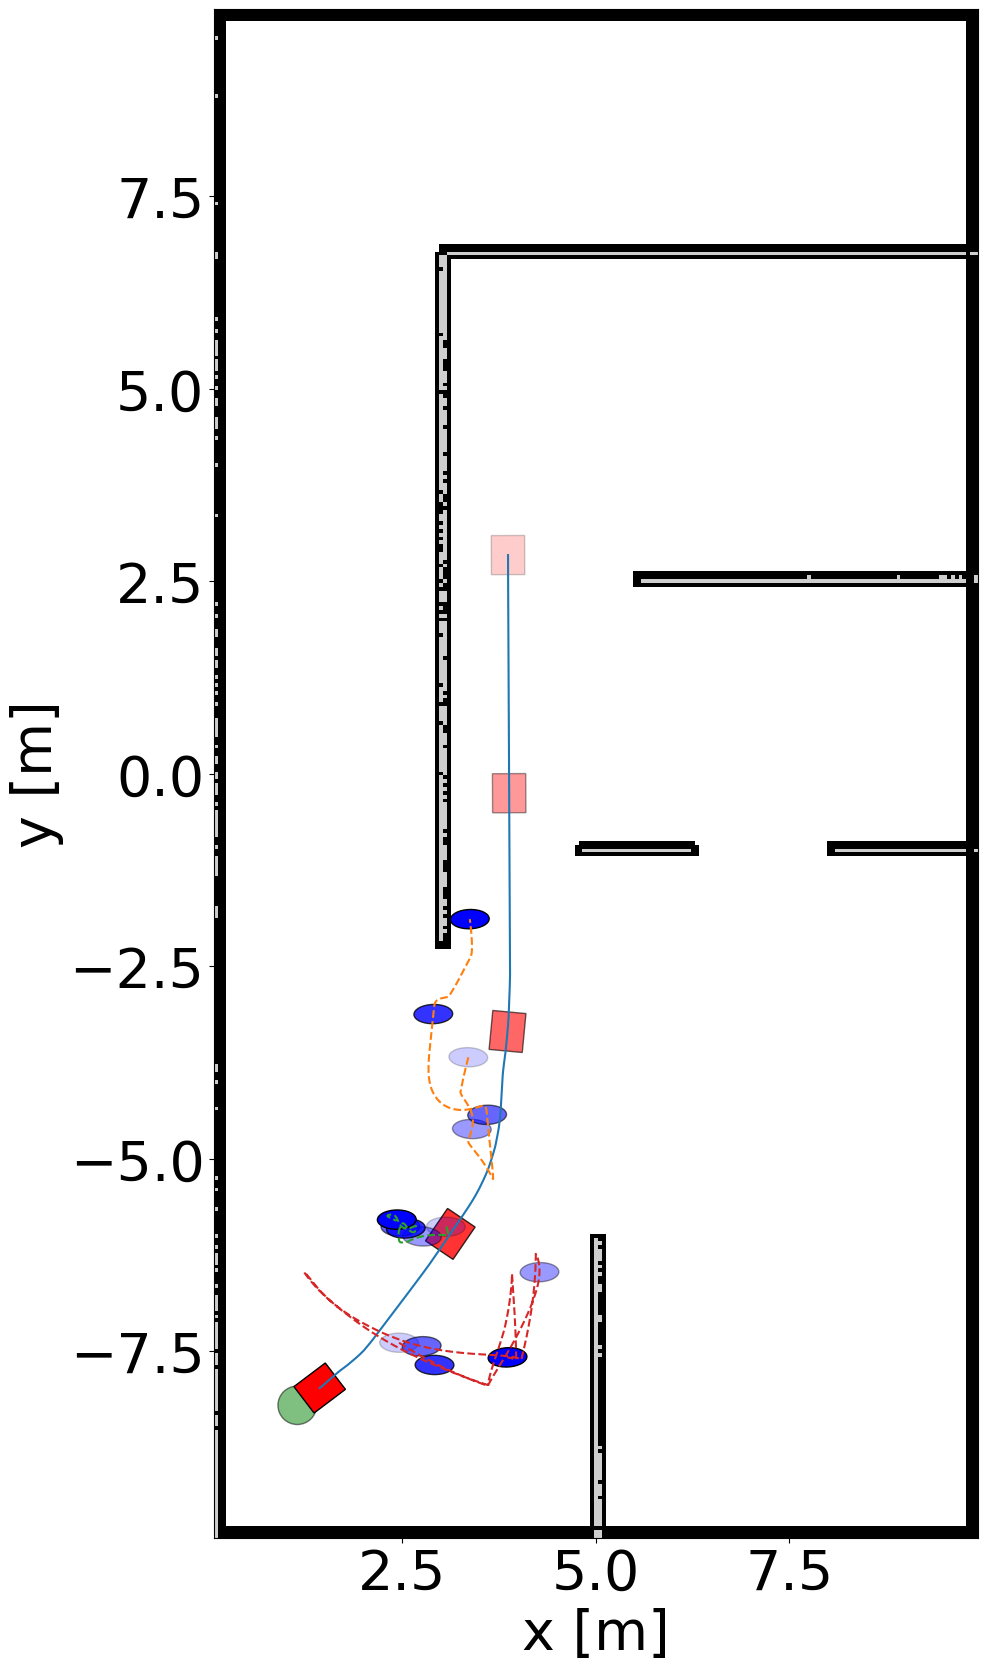

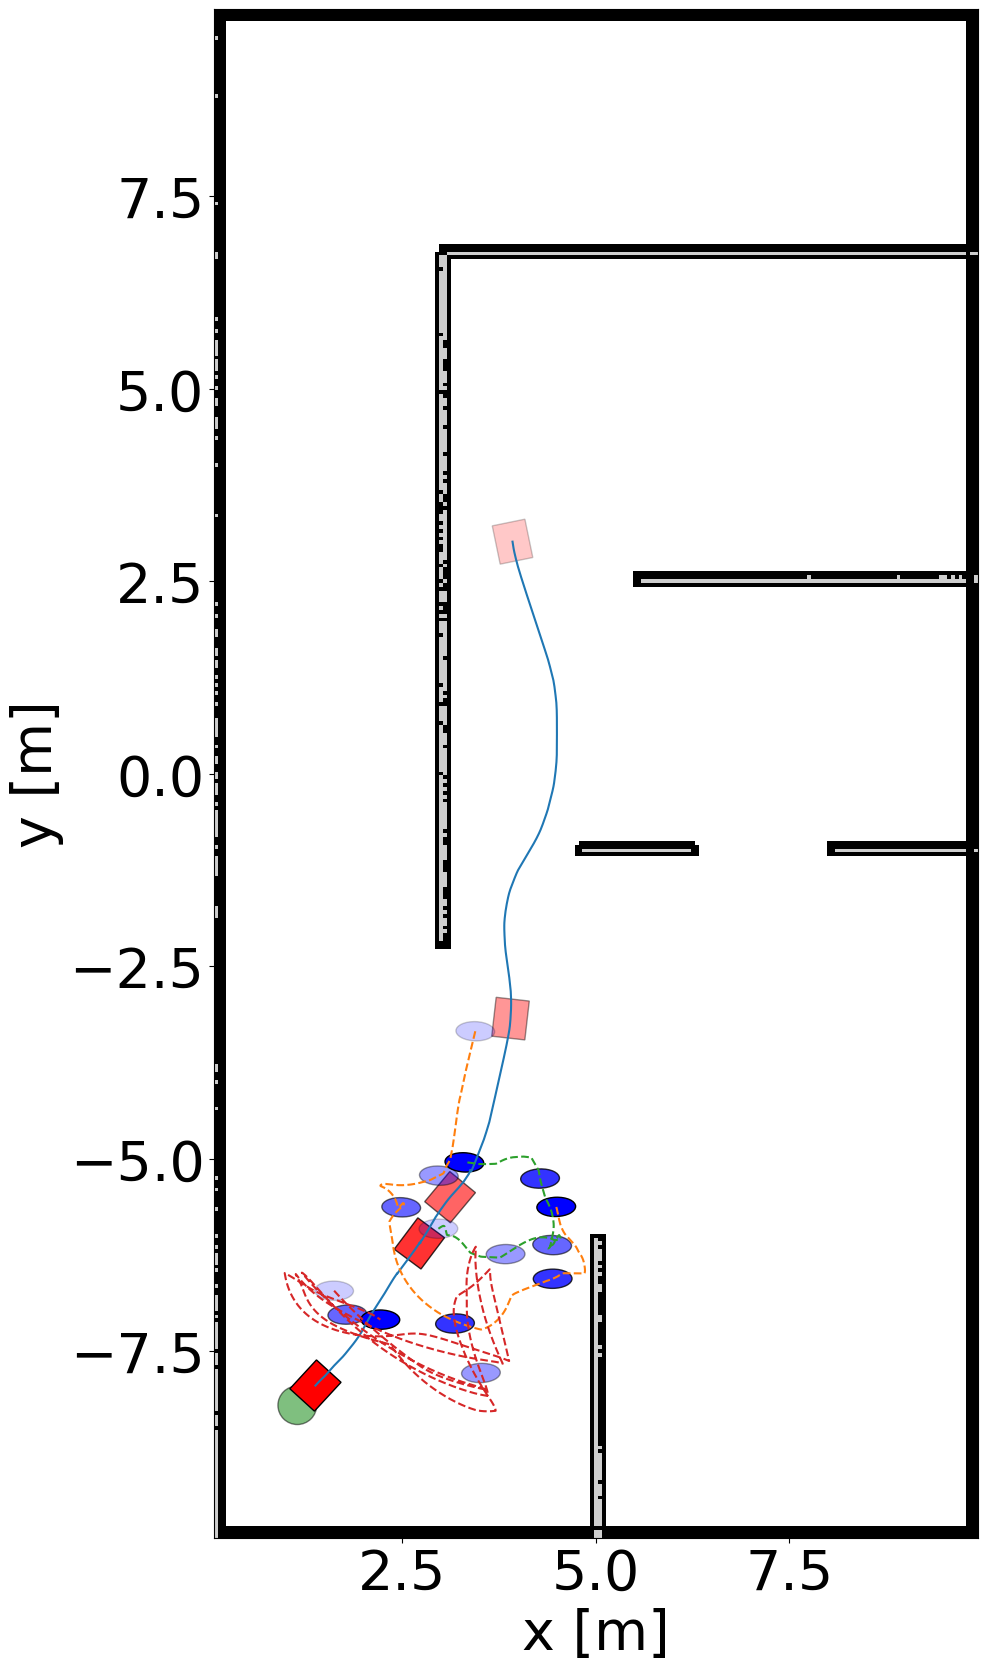

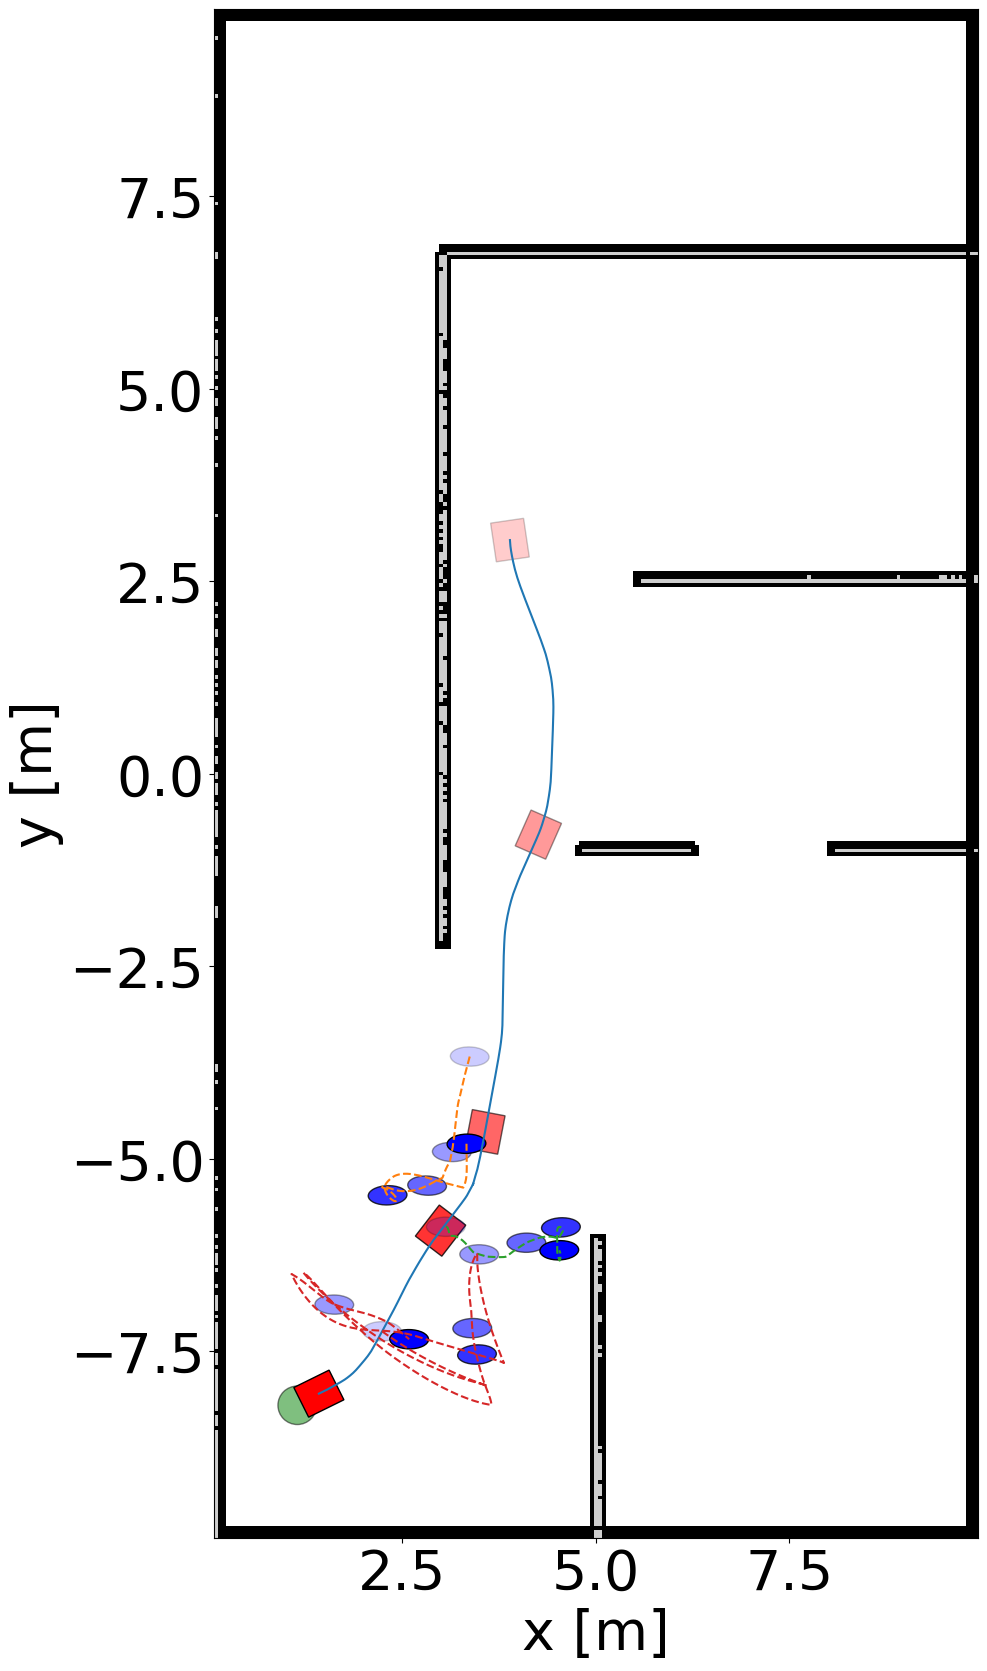

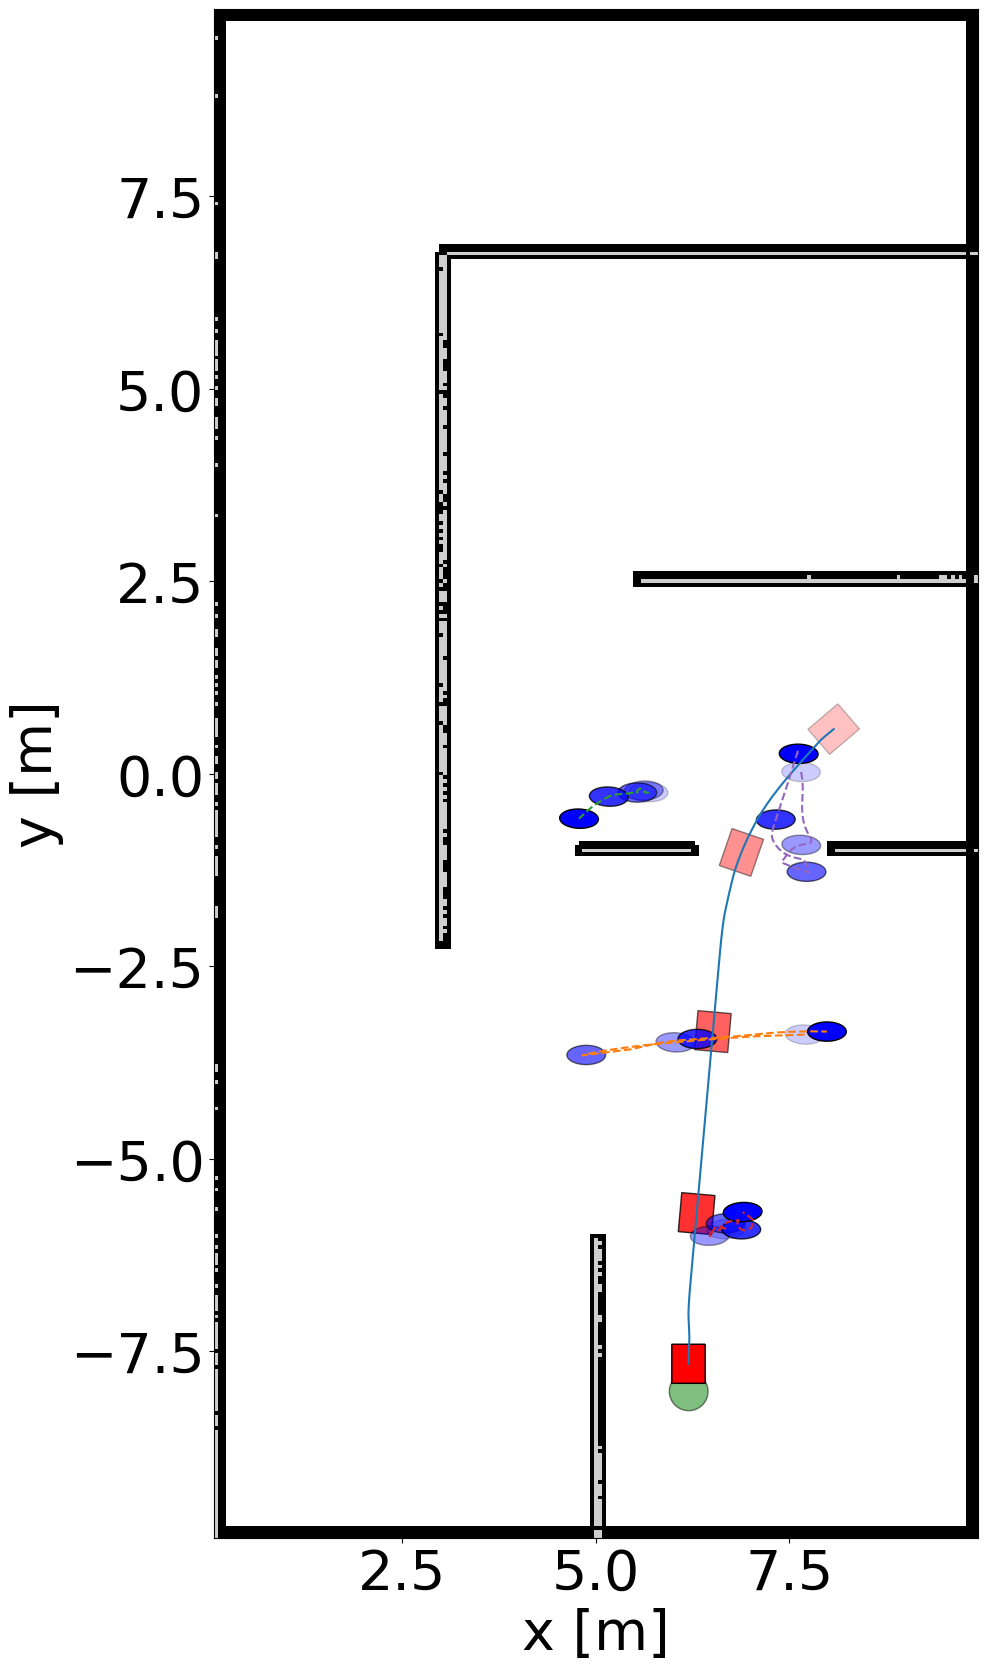

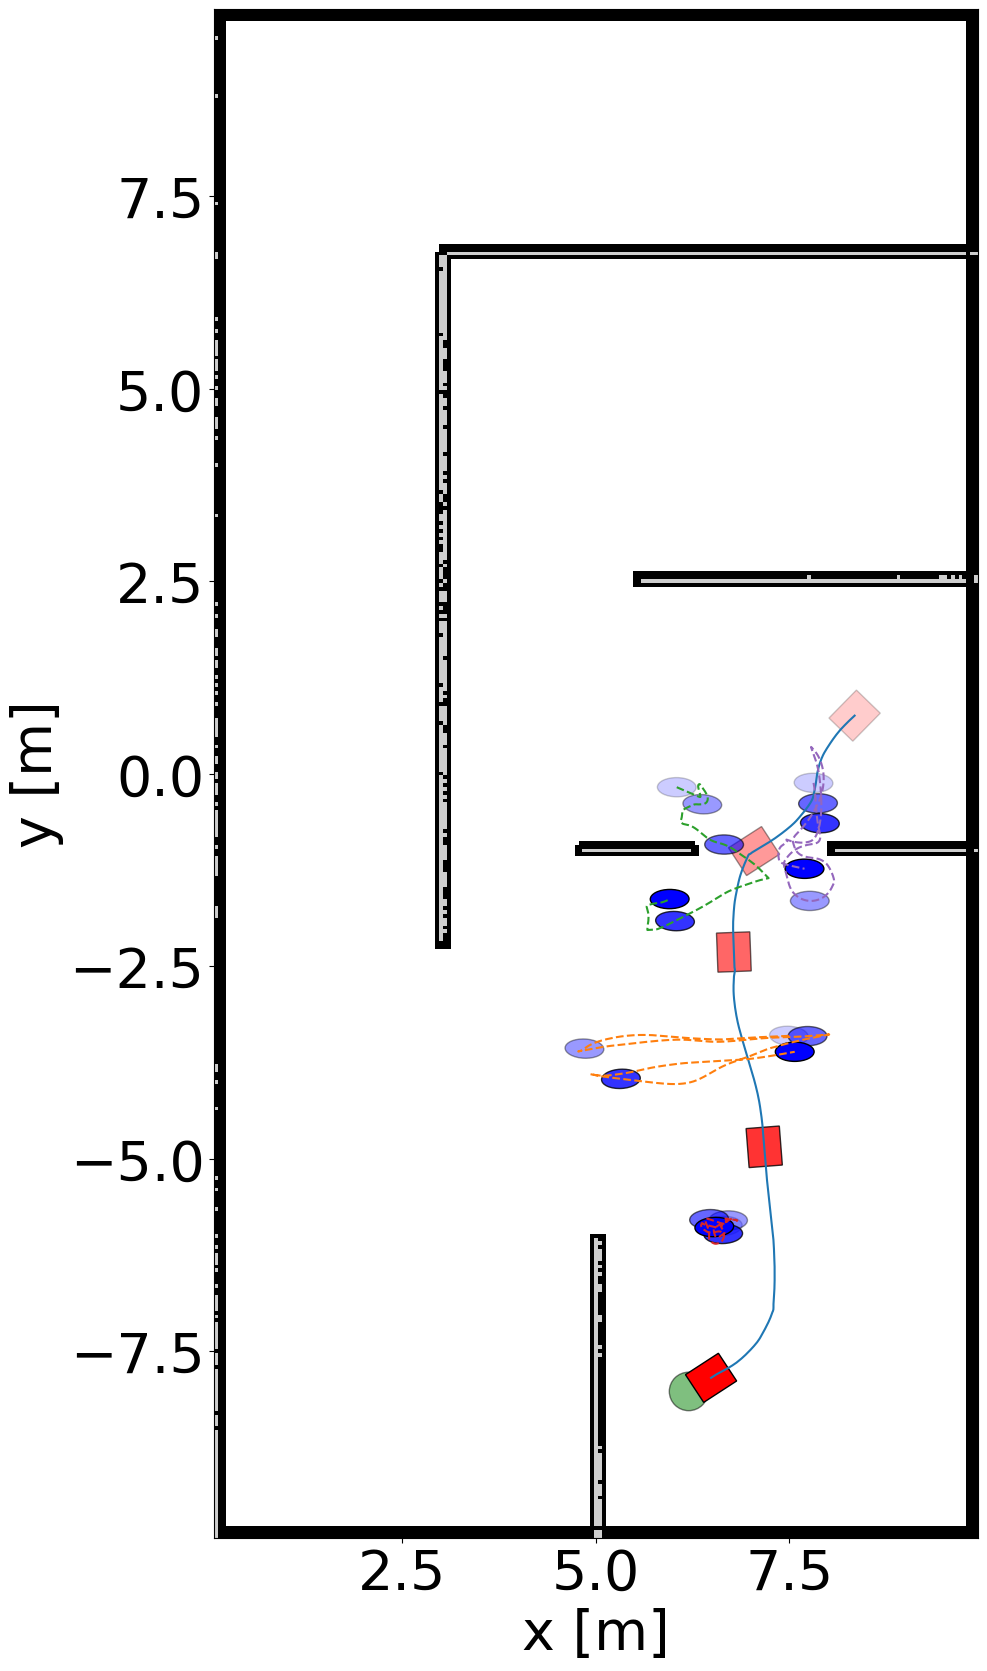

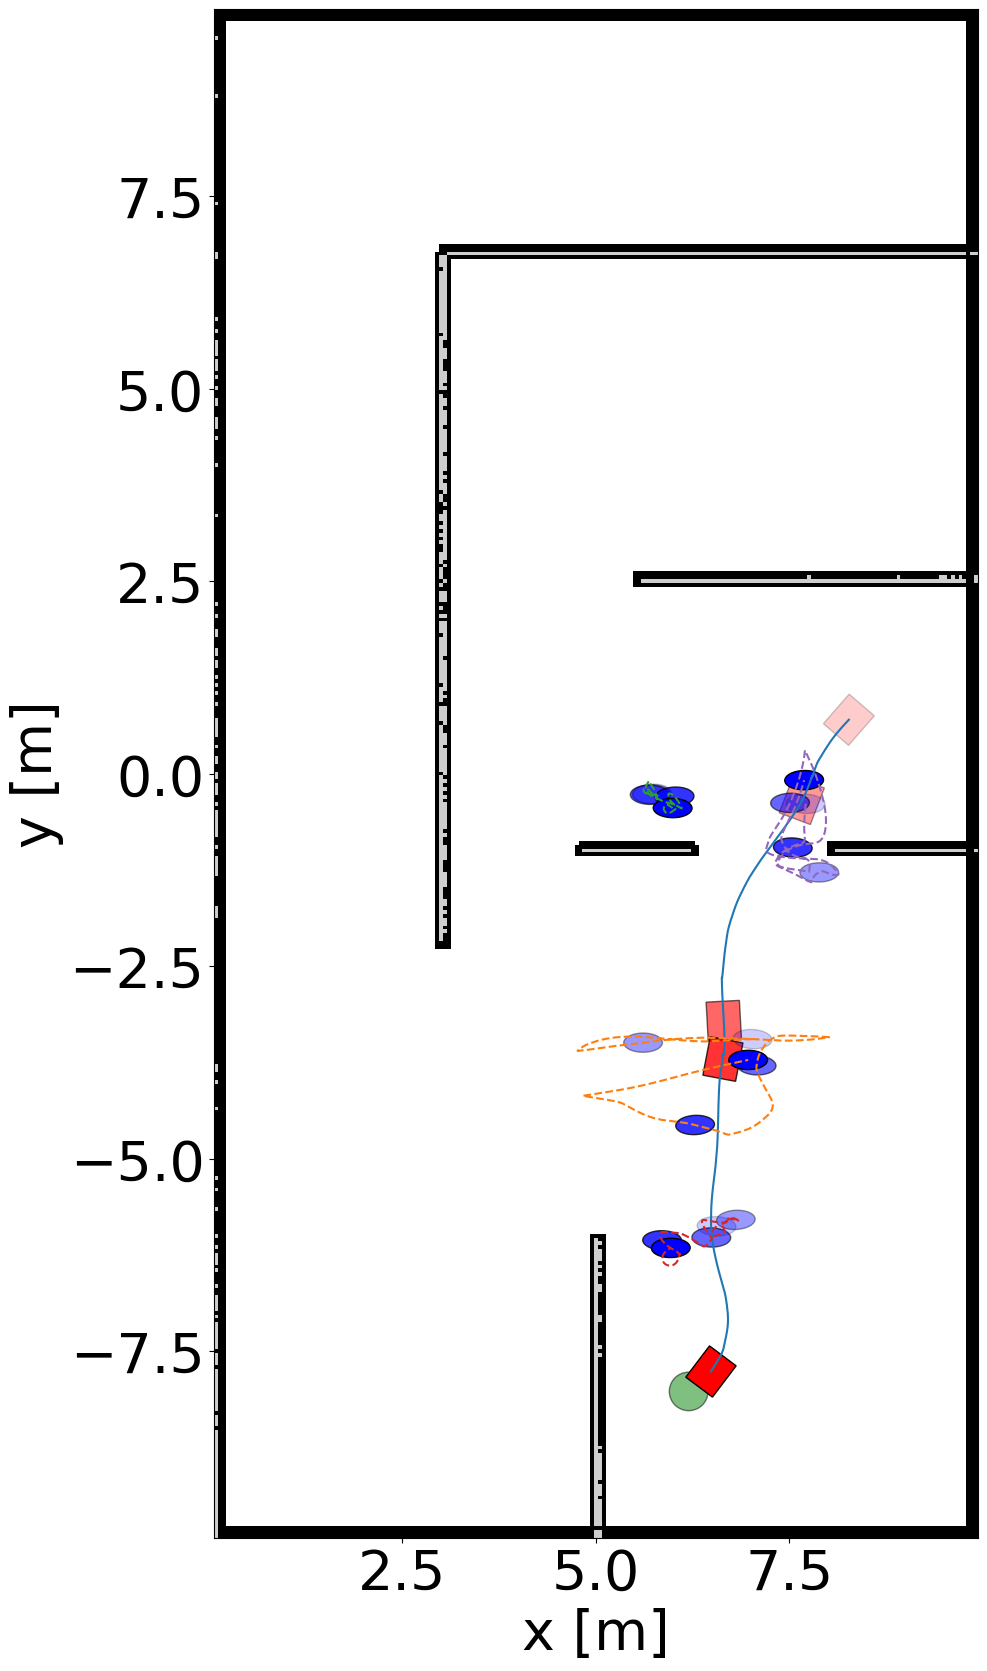

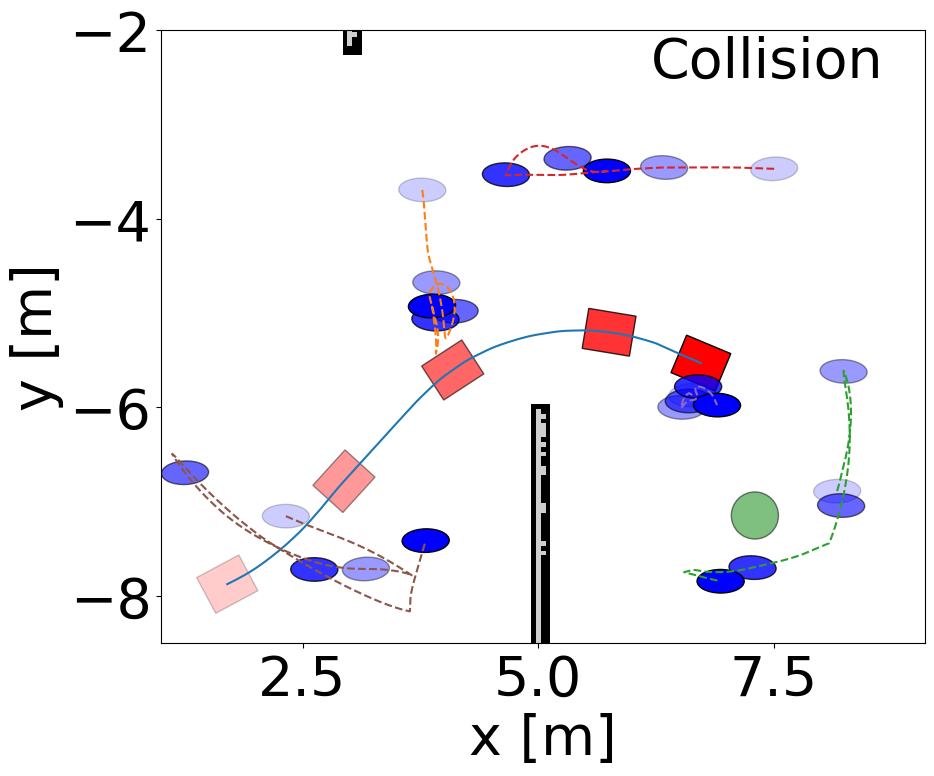

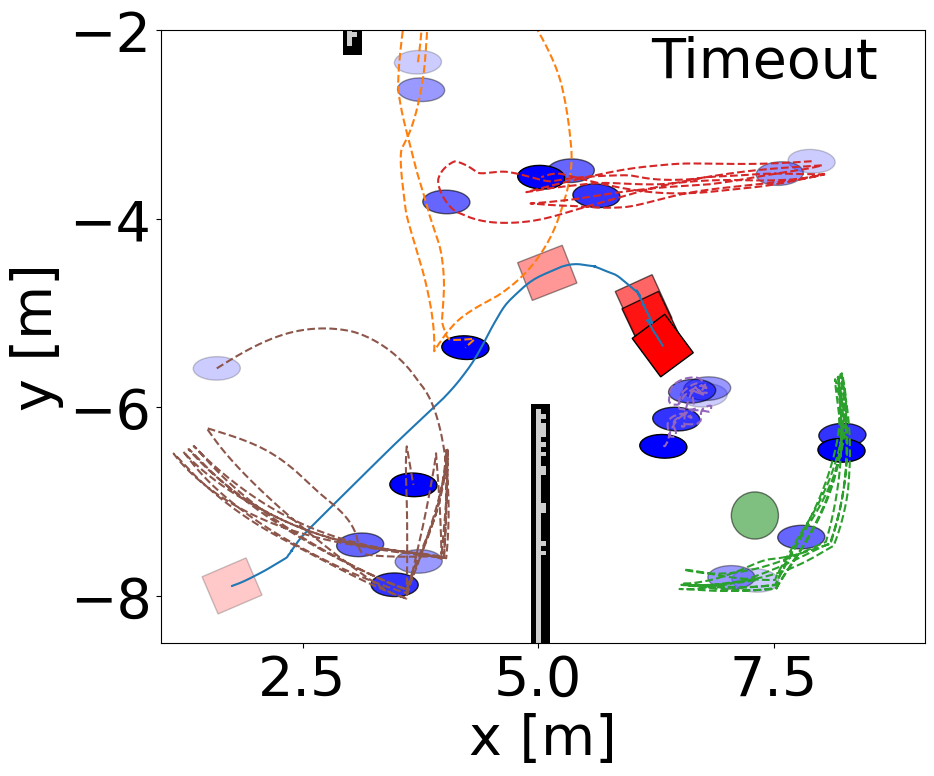

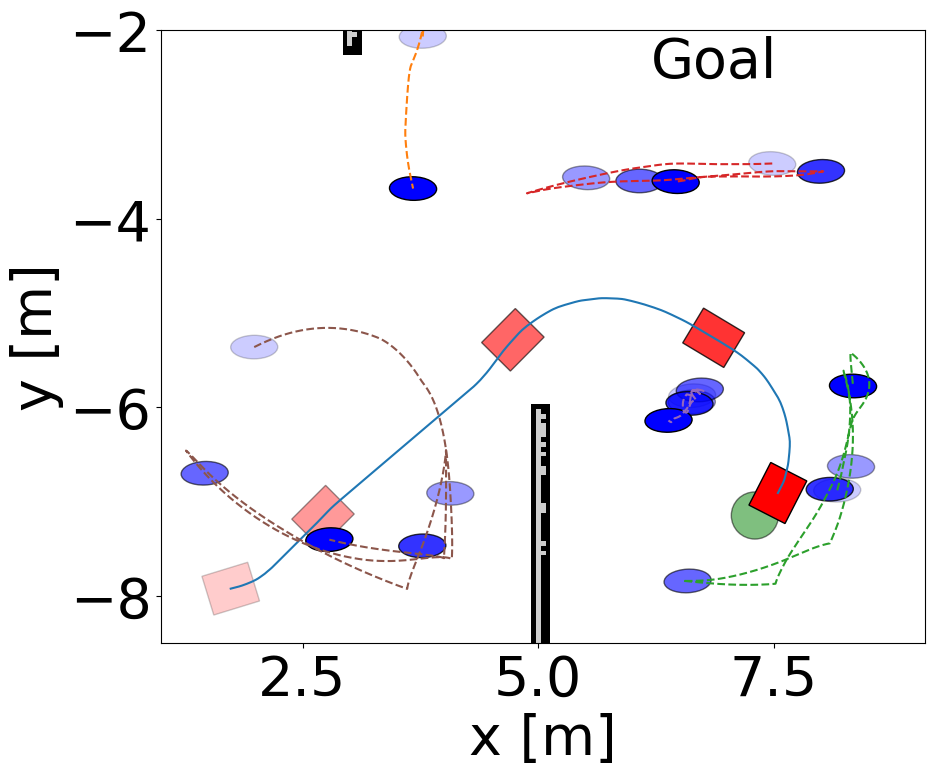

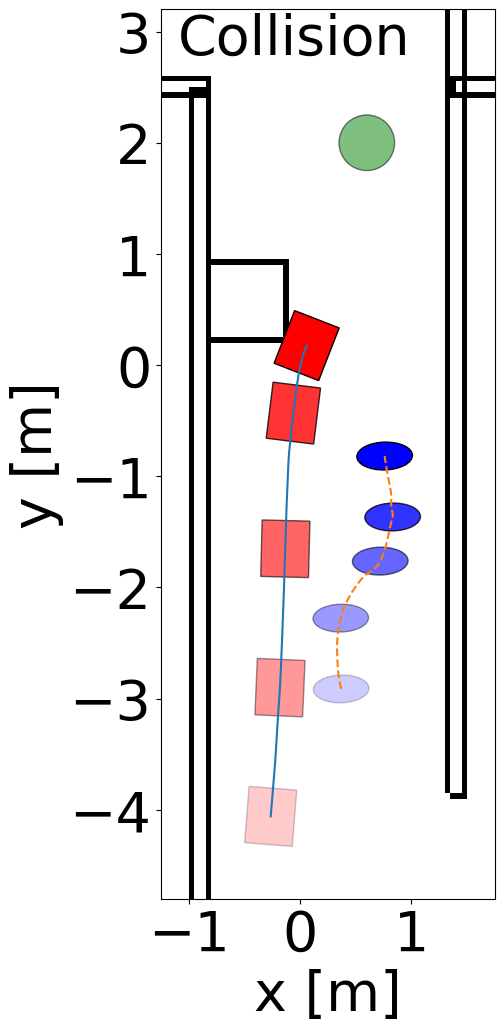

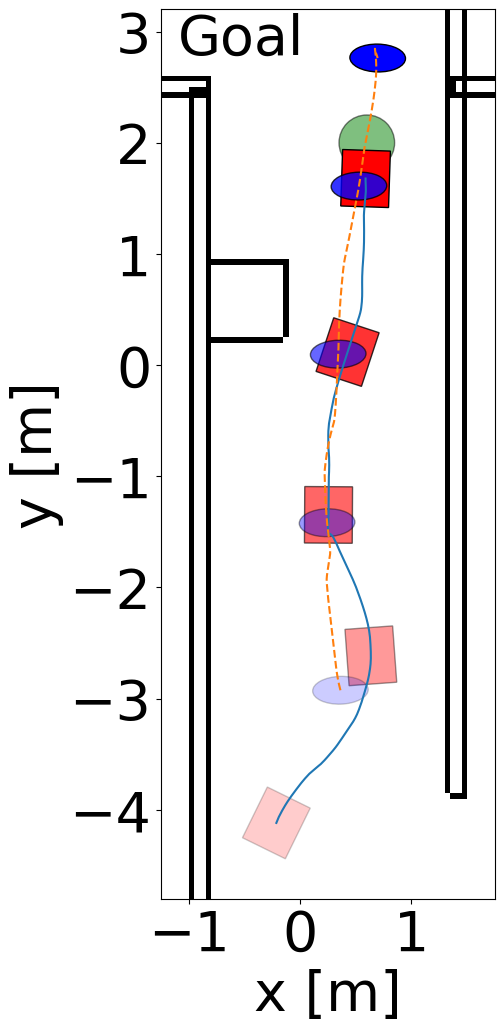

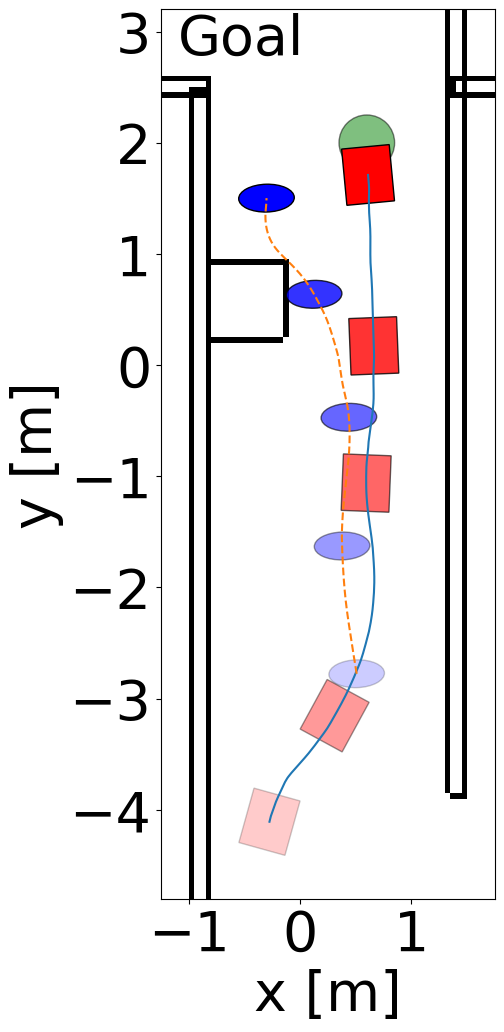

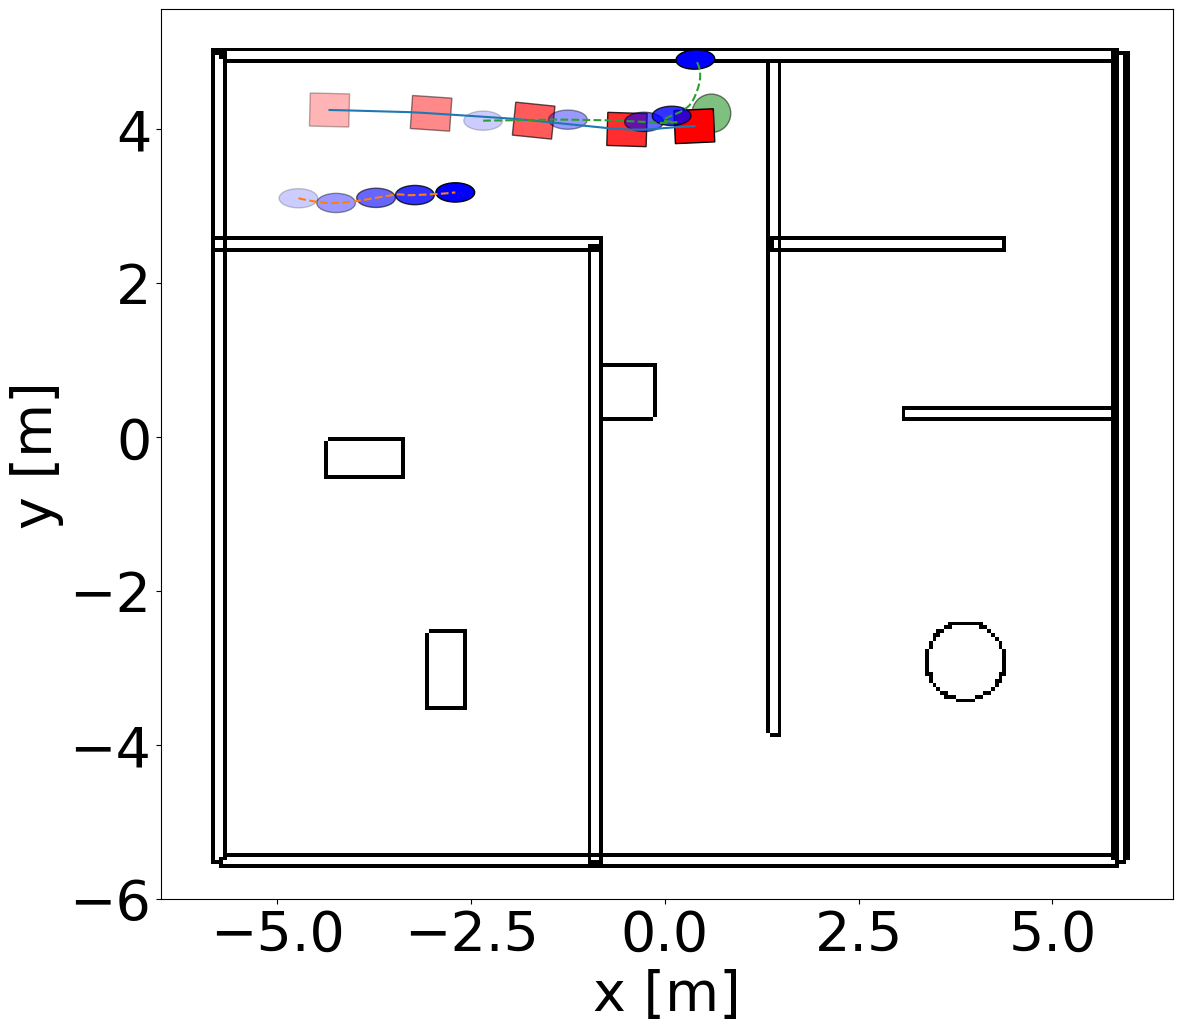

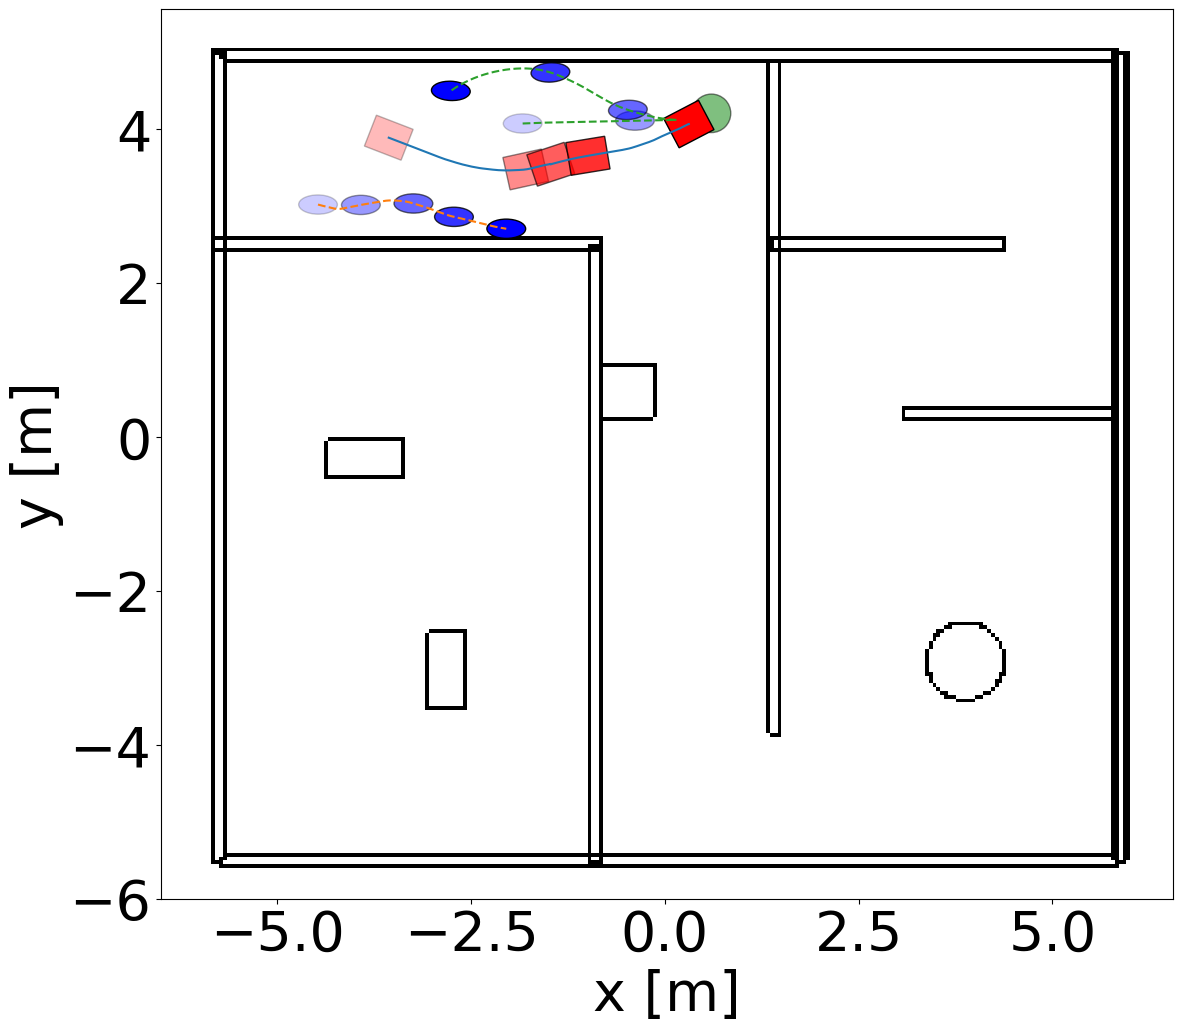

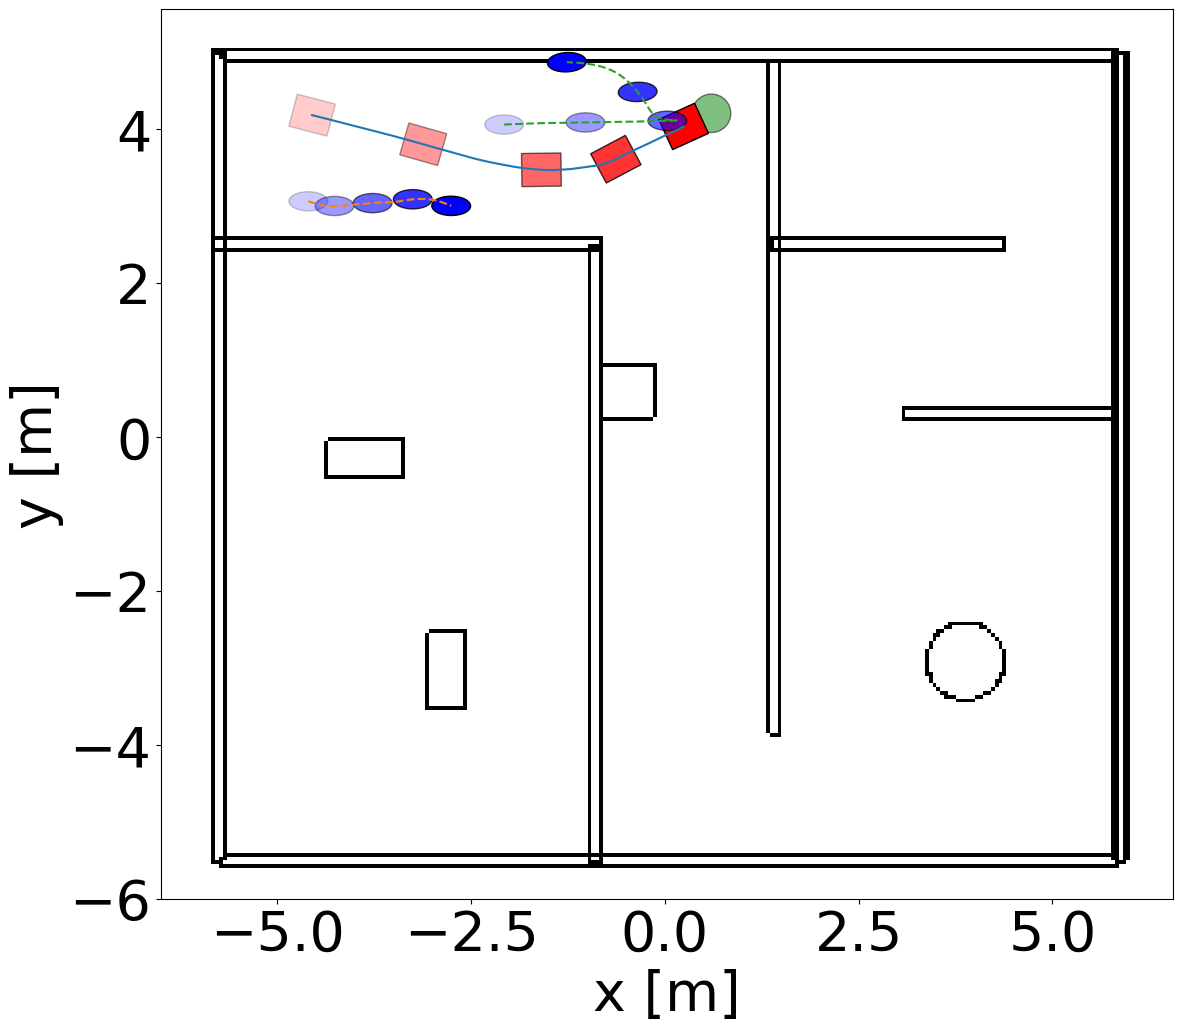

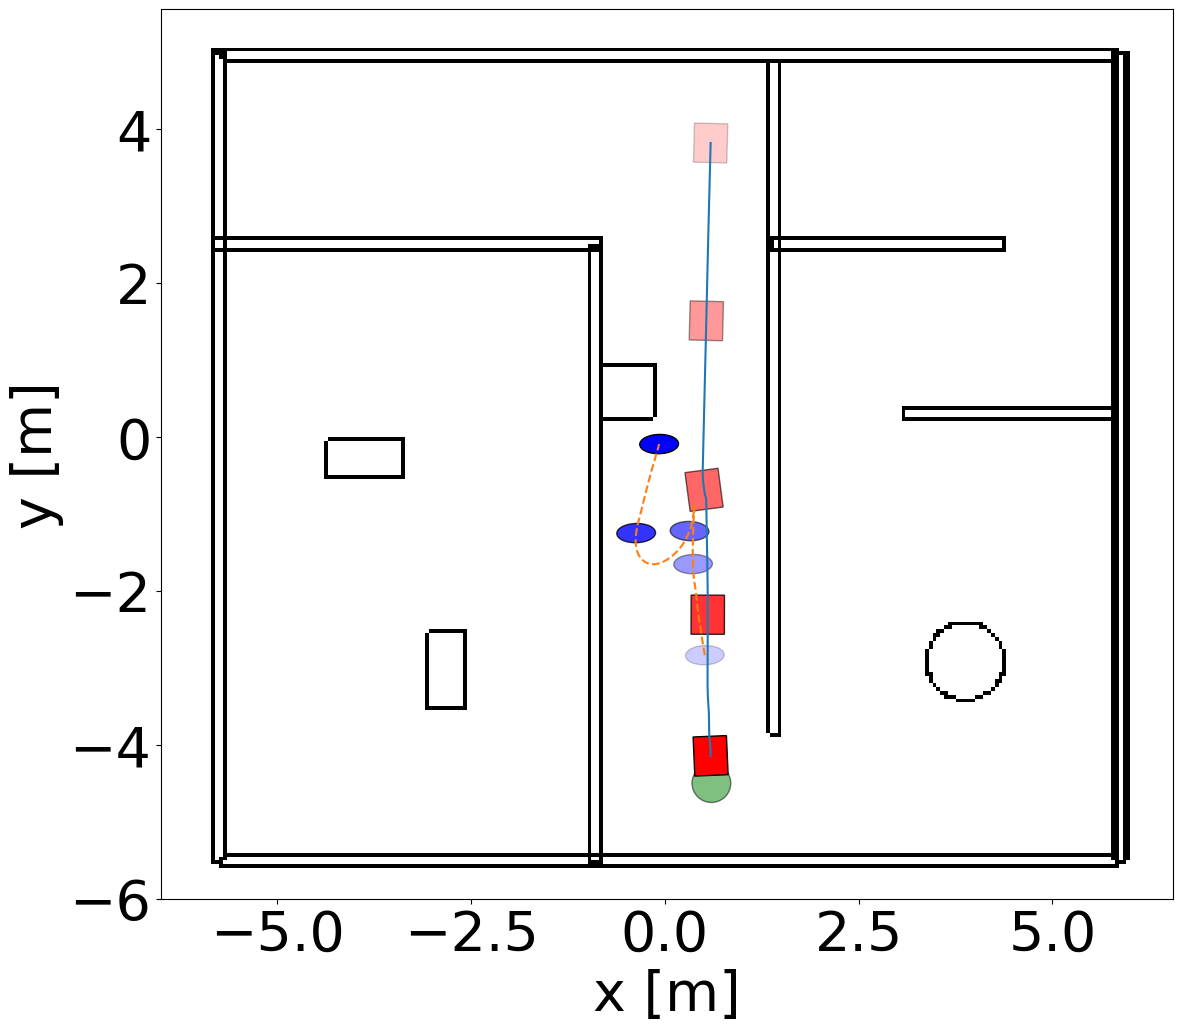

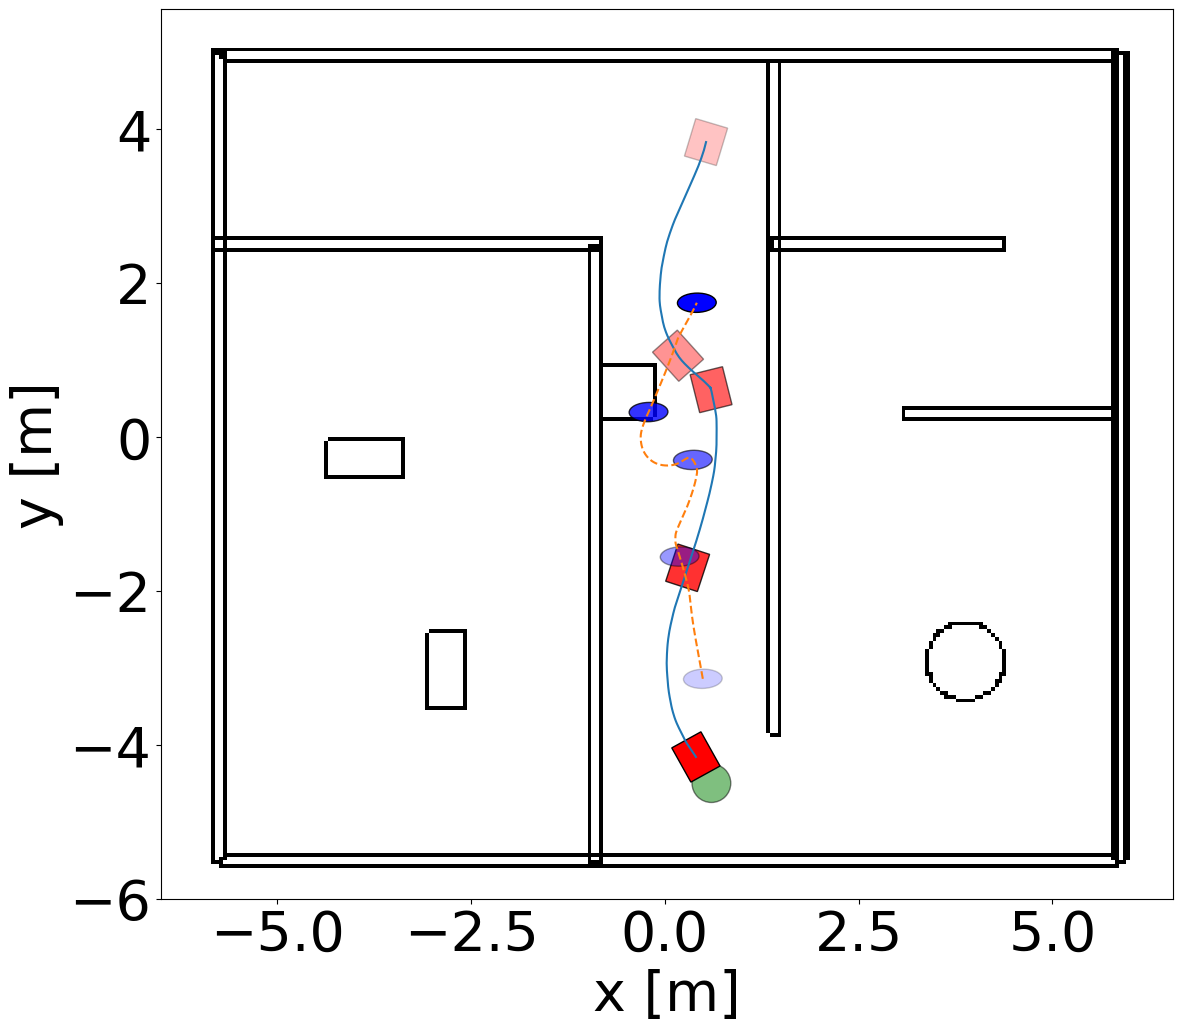

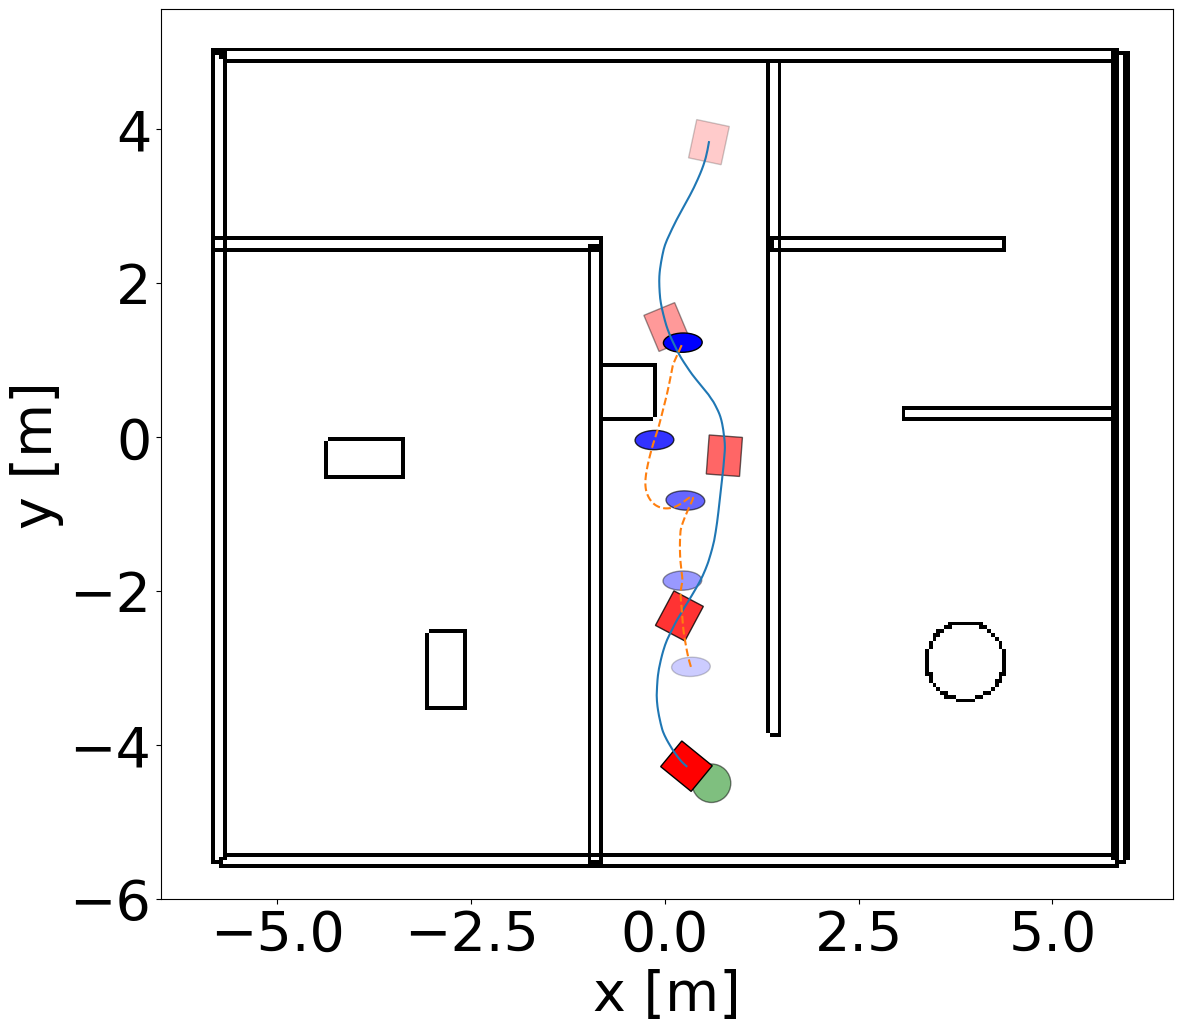

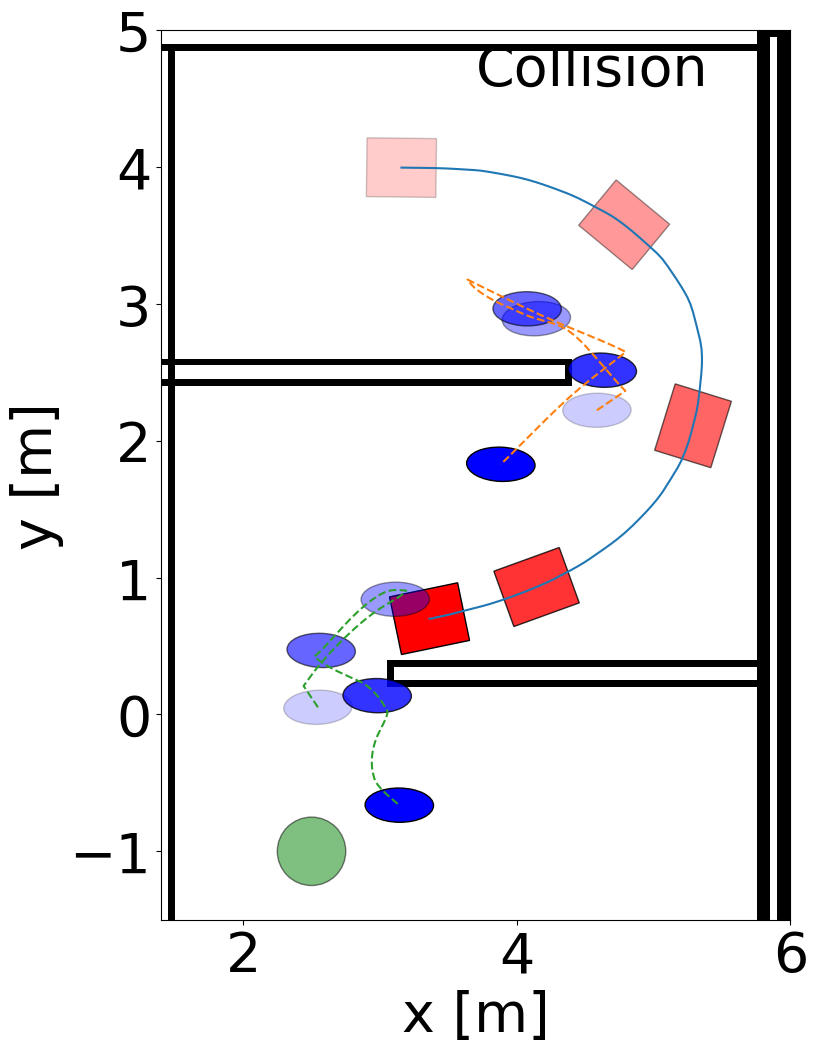

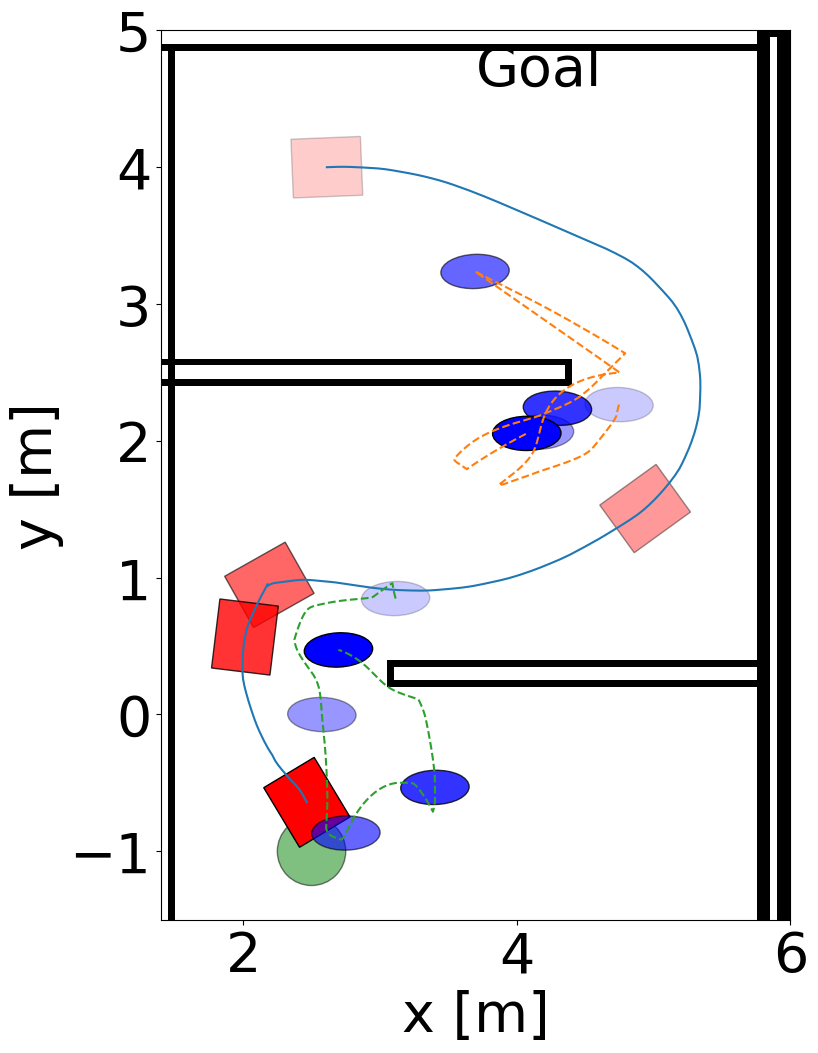

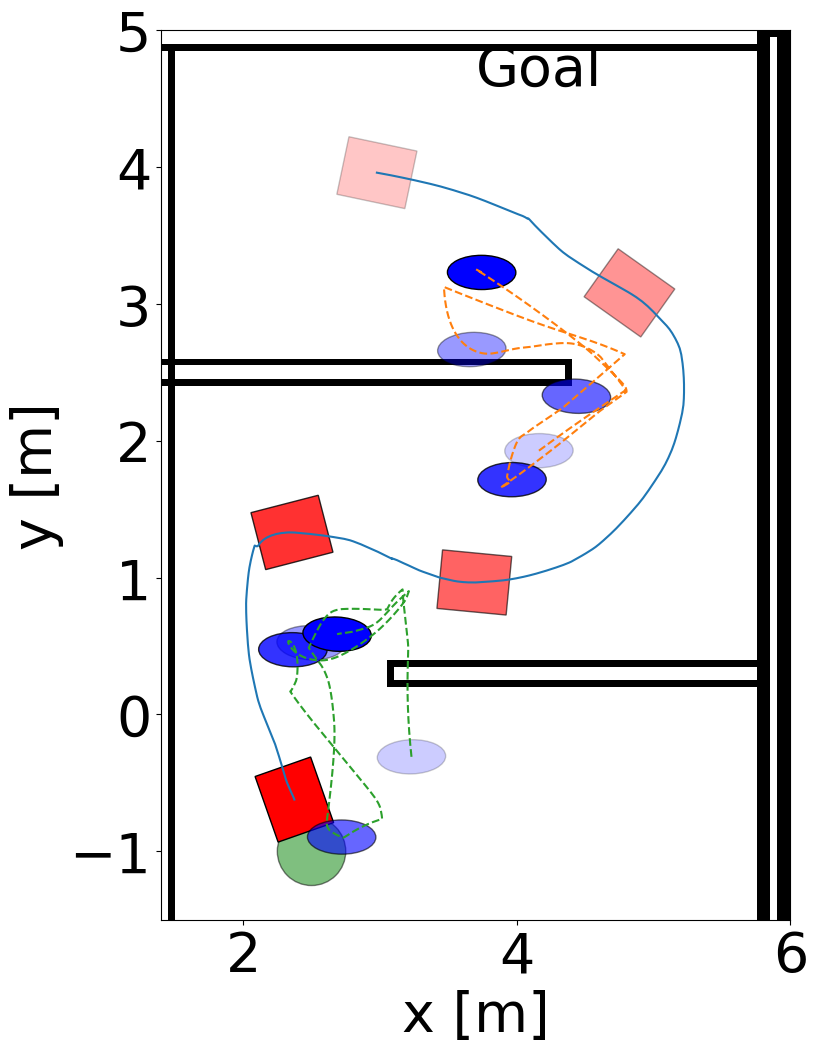

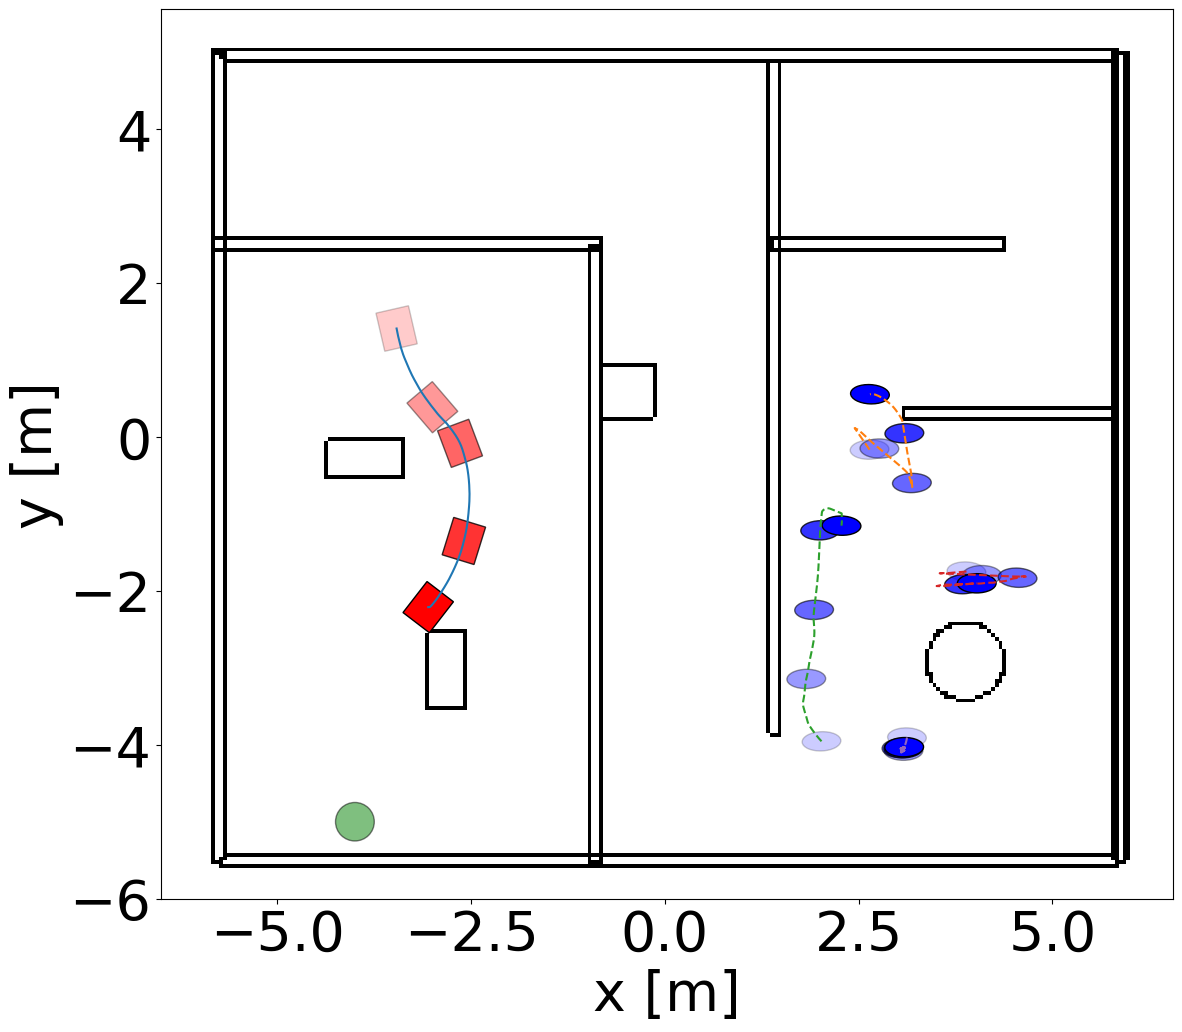

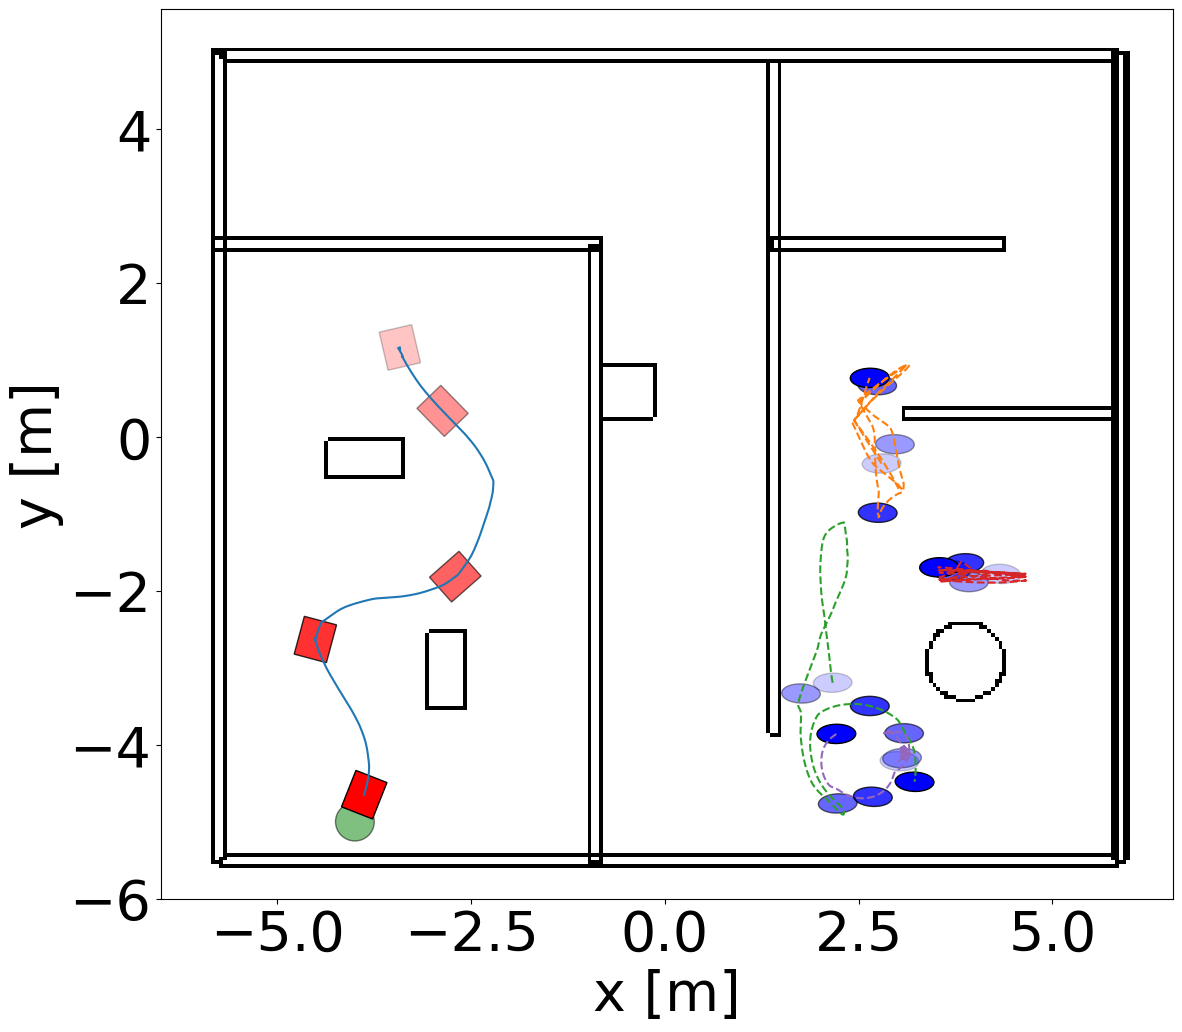

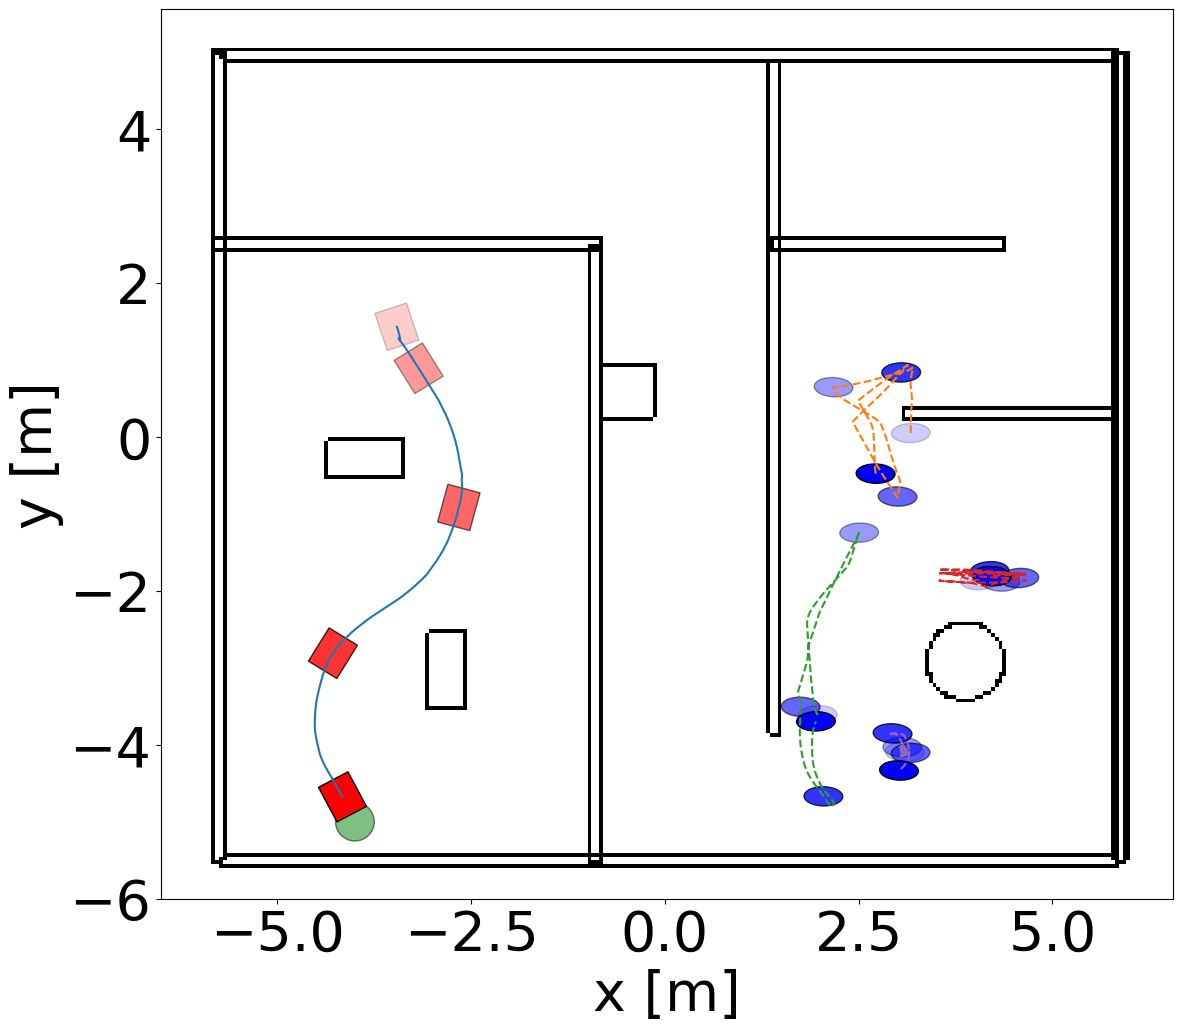

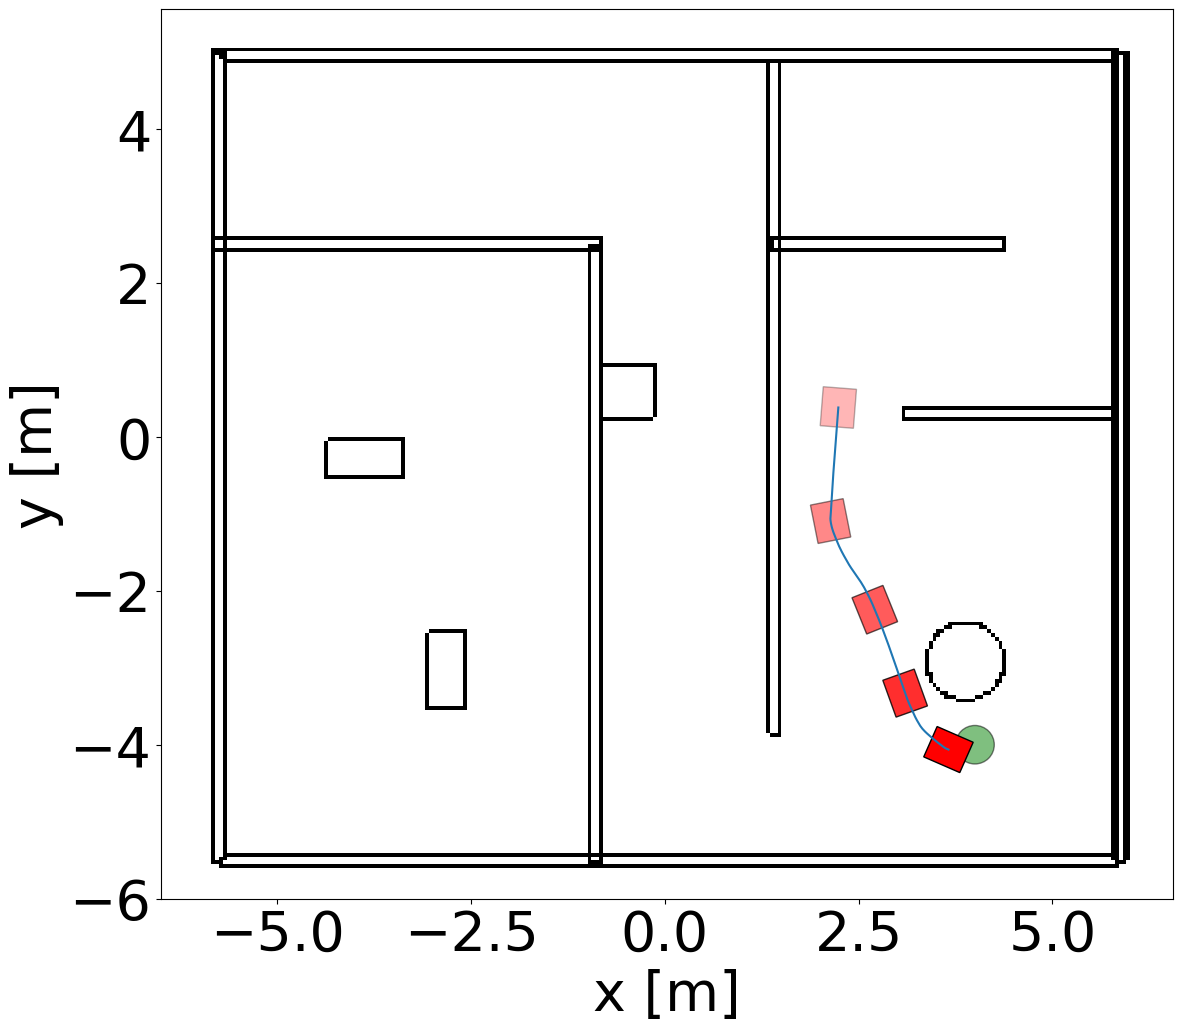

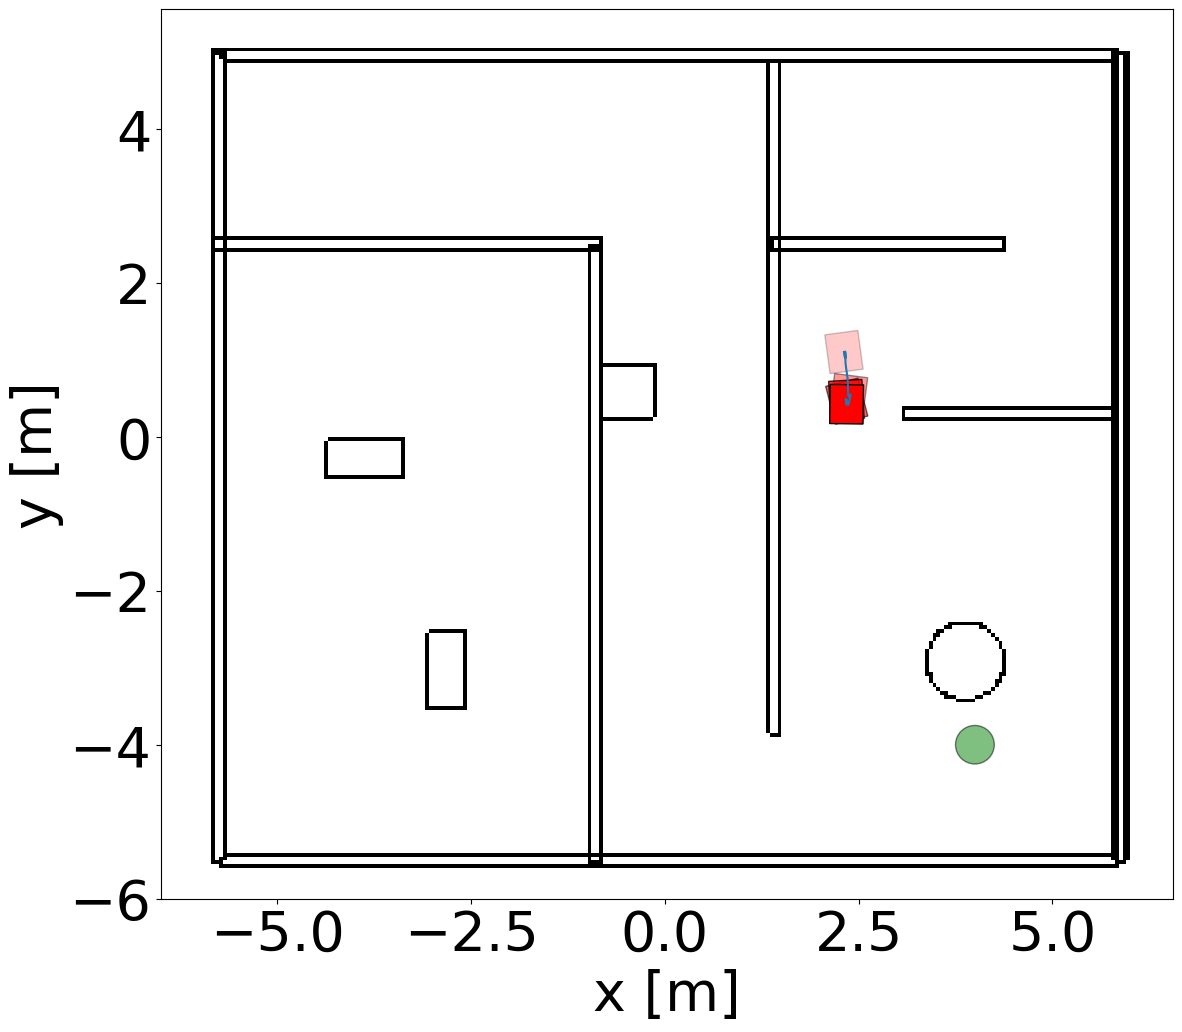

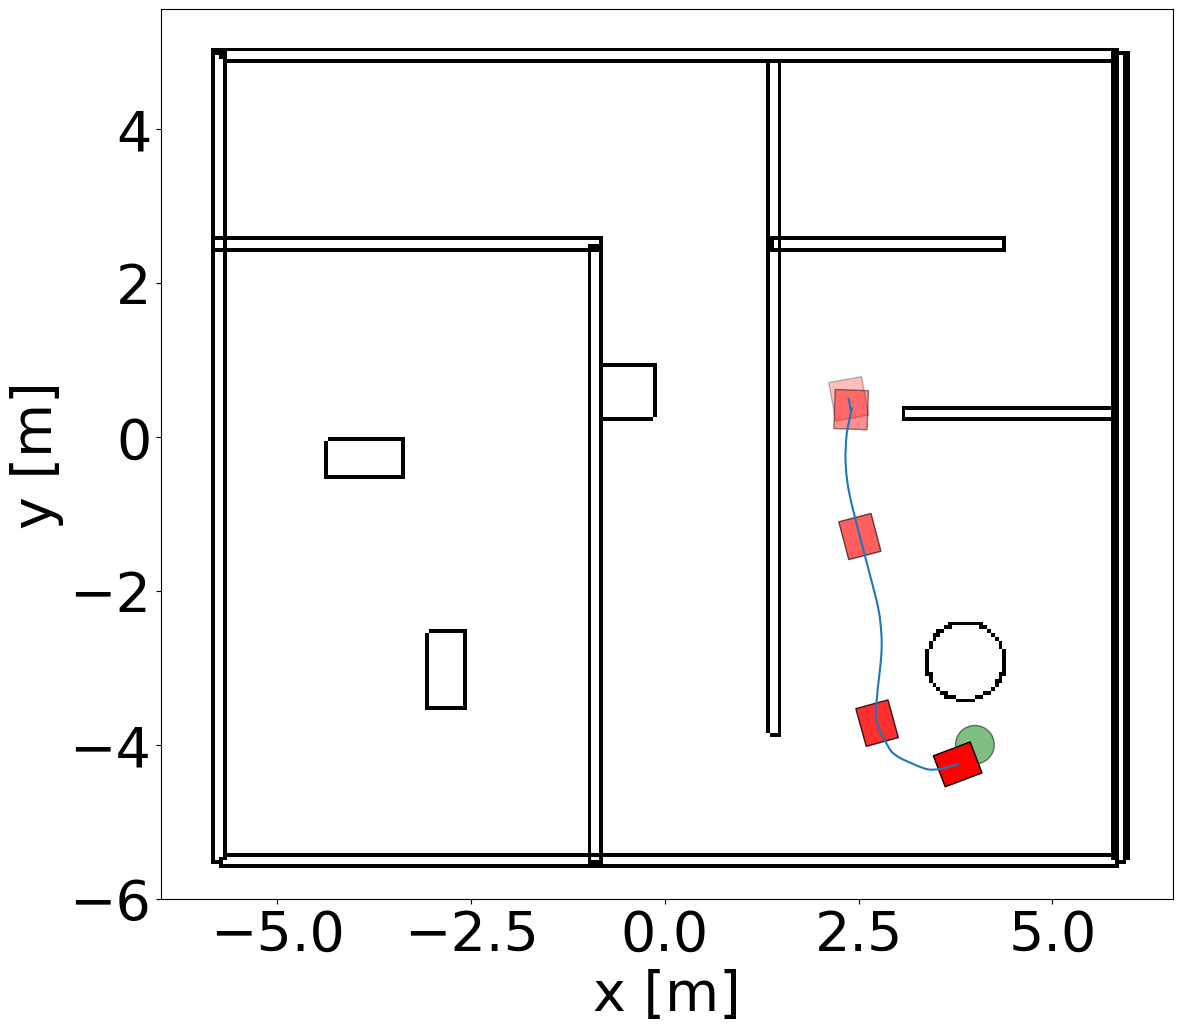

In [18]:
from matplotlib import pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np
from mpl_toolkits.axes_grid1.inset_locator import zoomed_inset_axes, mark_inset
import json

bag_paths= [f'bags/{row["method"]}/env_{int(row["environment"])}.csv' for i, row in df.iterrows()]
episodes_index = [int(row["environment"]) for i, row in df.iterrows()]
outcomes = [row['outcome'] for i, row in df.iterrows()]
# bag_path = 'bags/SAC_NR_2_2.0f/env_1.csv'
for bag_path, episode_index, outcome in zip(bag_paths, episodes_index, outcomes):

    min_x = 0 
    max_x = 0
    min_y = 0
    max_y = 0
    delta_x = 0
    delta_y = 0


    df_plot = pd.read_csv(bag_path)
    social_map_path = '/home/user/applr_ws/src/APPLR_social_nav/applr_social_nav/maps/social_nav_map.pgm'
    # crossing_map_path = '/home/user/applr_ws/src/APPLR_social_nav/applr_social_nav/maps/experiment.pgm'
    # passing_map_path = '/home/user/applr_ws/src/APPLR_social_nav/applr_social_nav/maps/corridor.pgm'
    # overtake_map_path = '/home/user/applr_ws/src/APPLR_social_nav/applr_social_nav/maps/experiment.pgm'
    social_env_map_path = '/home/user/applr_ws/src/APPLR_social_nav/applr_social_nav/maps/social_env_test_map.pgm'
    origin_social = [0.077, -9.92, 0]
    # origin_crossing = [-10.000000, -10.000000, 0.0]
    # origin_passing =  [-10.000000, -10.000000, 0.0]
    # origin_overtake = [-10.000000, -10.000000, 0.0]
    origin_social_env = [-6.500000, -6.000000, 0.0]

    # if episode_index in range(0, 8):
    #     map = plt.imread(social_map_path)
    #     origin = origin_social
    # elif episode_index in range(8,9):
    #     map = plt.imread(crossing_map_path)
    #     origin = origin_crossing
    # elif episode_index in range(9,10):
    #     map = plt.imread(passing_map_path)
    #     origin = origin_passing
    # elif episode_index in range(10,11):
    #     map = plt.imread(overtake_map_path)
    #     origin = origin_overtake

    if episode_index in range(0, 7):
        map = plt.imread(social_map_path)
        origin = origin_social
    elif episode_index in range(7,13):
        map = plt.imread(social_env_map_path)
        origin = origin_social_env

    resolution = 0.05 # m/cell

    x0 = origin[0]
    y0 = origin[1]
    x1 = x0 + map.shape[1]*resolution
    y1 = y0 + map.shape[0]*resolution
    size = (x1-x0, y1-y0)
    fig, ax = plt.subplots(1 , 1, figsize=size)
    # axins = zoomed_inset_axes(ax, zoom=4, loc='upper right')
    ax.imshow(map, extent=[x0, x1, y0, y1], aspect='auto', cmap='gray')
    # axins.imshow(map, extent=[x0, x1, y0, y1], aspect='auto', cmap='gray')

    # step_size = 200
    # GOAL goal and pose
    goal = goals.where(goals['environment'] == episode_index).dropna()
    goal_x = goal['x'].values[0]
    goal_y = goal['y'].values[0]
    goal_artist = mpatches.Circle((goal_x, goal_y), 0.25, facecolor='green', edgecolor='black', alpha=0.5)
    ax.add_patch(goal_artist)

    # JACKAL
    jackal_trajectory = df_plot[['jackal/x','jackal/y', 'jackal/yaw']]
    jackal_trajectory.rename(columns={'jackal/x':'x', 'jackal/y':'y', 'jackal/yaw':'yaw'}, inplace=True)
    jackal_trajectory.interpolate(inplace=True)
    jackal_trajectory.dropna()
    jackal_trajectory.plot(x='x',y='y', ax=ax, label='Jackal')
    # jackal_trajectory.plot(x='x',y='y', ax=axins, label='Jackal')
    steps = np.linspace(jackal_trajectory.first_valid_index(), jackal_trajectory.last_valid_index(), 5).astype(int)

    import copy

    
    # FONTSIZE
    if episode_index == 2:
        fontsize = 60
    else:
        fontsize = 40  

    for i in steps:
        jackal_x = jackal_trajectory.iloc[i]['x']
        jackal_y = jackal_trajectory.iloc[i]['y']
        jackal_yaw = jackal_trajectory.iloc[i]['yaw']
        jackal_width = 0.508
        jackal_height = 0.430
        alpha = 0.2 + 0.8 * ((1 / len(jackal_trajectory)) * i)
        # jackal_artist = mpatches.Rectangle((jackal_x + (jackal_height/2) , jackal_y + (jackal_width /2)), width=0.508, height=0.430, facecolor='red', edgecolor='black', angle=jackal_yaw, alpha= alpha)
        jackal_artist = mpatches.Rectangle(((jackal_x - (jackal_width /2)) , (jackal_y - (jackal_height/2)) ) , width=0.508, height=0.430, facecolor='red', edgecolor='black', angle=np.rad2deg(jackal_yaw), alpha= alpha, rotation_point='center')
        ax.add_patch(jackal_artist)
        # j_a = copy.deepcopy(jackal_artist)
        # axins.add_patch(j_a)
        # if i == steps[0]:
        #     ax.text(jackal_x, jackal_y, f'1', fontsize=fontsize, color='darkred')
        # if i == steps[2]:
        #     ax.text(jackal_x, jackal_y, f'2', fontsize=fontsize, color='darkred')
        # if i == steps[-1]:
        #     ax.text(jackal_x, jackal_y, f'3', fontsize=fontsize, color='darkred')





    # PEOPLE

    people2plot = []
    # people2plot = [0, 1, 2, 3, 4, 5, 6, 7, 8]
    if episode_index in [1]: # social nav 1 passing
        people2plot = [1]
    elif episode_index in [2]: # social nav 3 overtake
        people2plot = [2,12]
    elif episode_index in [3]: # social nav 4 crossing
        people2plot = [5,6,14]
    elif episode_index in [4]: # social nav 6 crossing
        people2plot = [4,10,13]
    elif episode_index in [5]: # social nav 7 crossing
        people2plot = [8,9,11,14]
    elif episode_index in [6]: # social nav 9 crossing
        people2plot = [4,7,8,11,13]
    elif episode_index in [7]: # social env 2
        people2plot = [3]
    elif episode_index in [8]: # social env 3
        people2plot = [1, 2]
    elif episode_index in [9]: # social env 4
        people2plot = [3]
    elif episode_index in [10]: # social env 9
        people2plot = [7,8]
    elif episode_index in [11]: # social env 9
        people2plot = [8, 9, 10, 11]

    people_trajectories = []
    for k in range(len(people2plot)):
        i = people2plot[k]
        person_trajectory = df_plot[['person_'+str(i-1)+'/x','person_'+str(i-1)+'/y', 'person_'+str(i-1)+'/yaw']]
        person_trajectory.rename(columns={'person_'+str(i-1)+'/x':'x', 'person_'+str(i-1)+'/y':'y', 'person_'+str(i-1)+'/yaw':'yaw'}, inplace=True)
        person_trajectory.interpolate(inplace=True)
        # person_trajectory.dropna()
        people_trajectories.append(person_trajectory)
        person_trajectory.plot(x='x',y='y', ax=ax, label='Person '+str(i), style='--')
        # person_trajectory.plot(x='x',y='y', ax=axins, label='Person '+str(i), style='--')
        person_steps = np.linspace(person_trajectory.first_valid_index(), person_trajectory.last_valid_index(), 5).astype(int)
        for j in person_steps:
        # for i in range(0, len(person_trajectory)):
            person_x = person_trajectory.iloc[j]['x']
            person_y = person_trajectory.iloc[j]['y']
            person_yaw = person_trajectory.iloc[j]['yaw']
            person_width = 0.5
            person_height = 0.25
            # alpha = 0.2 + 0.8 * ((1 / len(person_trajectory/ step_size)) * i)
            alpha = 0.2 + 0.8 * ((1 / len(person_trajectory)) * j)
            person_artist = mpatches.Ellipse((person_x , person_y ), width=person_width, height=person_height, facecolor='blue', edgecolor='black', angle=person_yaw, alpha=alpha)
            ax.add_patch(person_artist)
            if i in [10,12,6] and episode_index in [2,3,6]:
                continue
            

            # if j == person_steps[0]:
            #     ax.text(person_x, person_y, f'1', fontsize=fontsize, color='darkblue')
            # if j == person_steps[2]:
            #     ax.text(person_x, person_y, f'2', fontsize=fontsize, color='darkblue')
            # if j == person_steps[-1]:
            #     ax.text(person_x, person_y, f'3', fontsize=fontsize, color='darkblue')
            # axins.add_patch(person_artist)

    if episode_index == 2:
        ax.axis([0.0,3.0,1.5,8.4])
        ax.set_aspect('equal')
        ax.text(1.0,8.0, f'{outcome}', fontsize=fontsize)
    elif episode_index == 3:
        ax.axis([3.0,9.9,-1.0,6.8])
        ax.set_aspect('equal')
        ax.text(7.3, 6.3, f'{outcome}', fontsize=fontsize)
    elif episode_index == 6:
        ax.axis([1.0,9.1,-8.5,-2.0])
        ax.set_aspect('equal')
        ax.text(6.2, -2.5, f'{outcome}', fontsize=fontsize)
    elif episode_index == 7:
        ax.axis([-1.25,1.75,-4.8,3.2])
        ax.set_aspect('equal')
        ax.text(-1.1, 2.8, f'{outcome}', fontsize=fontsize)
    elif episode_index == 10:
        ax.axis([1.4,6.0,-1.5,5.0])
        ax.set_aspect('equal')
        ax.text(3.7, 4.6, f'{outcome}', fontsize=fontsize)
    
    ax.set_xlabel('x [m]', fontsize=fontsize)
    ax.set_ylabel('y [m]', fontsize=fontsize)
    ax.tick_params(axis='both', which='major', labelsize=fontsize)

    # write some text at the top right


    traj_path = bag_path.replace('.csv', '.png')
    traj_path = traj_path.replace('bags/', 'trajectories/')
    os.makedirs(os.path.dirname(traj_path), exist_ok=True)
    ax.legend().remove()
    fig.savefig(traj_path, bbox_inches='tight')


/tmp/ipykernel_2616581/855225211.py:49: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  jackal_trajectory.rename(columns={'jackal/x':'x', 'jackal/y':'y', 'jackal/yaw':'yaw'}, inplace=True)
/tmp/ipykernel_2616581/855225211.py:50: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  jackal_trajectory.interpolate(inplace=True)
/tmp/ipykernel_2616581/855225211.py:107: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  person_trajectory.rename(columns={'

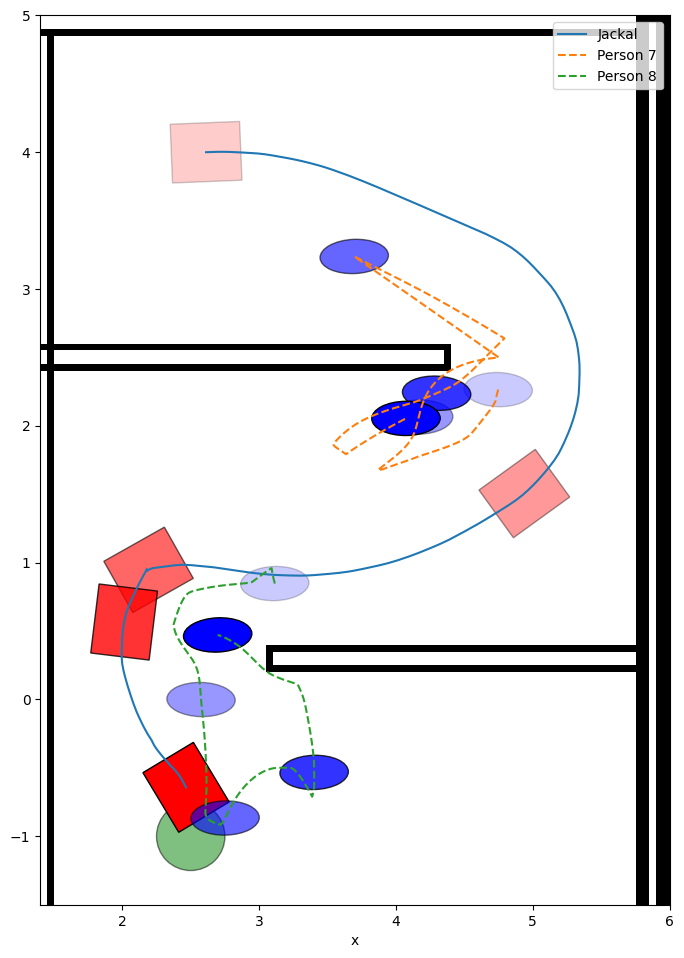

In [19]:

bag_path = 'bags/SFW/env_10.csv'
episode_index = 10
min_x = 0 
max_x = 0
min_y = 0
max_y = 0
delta_x = 0
delta_y = 0


df_plot = pd.read_csv(bag_path)
social_map_path = '/home/user/applr_ws/src/APPLR_social_nav/applr_social_nav/maps/social_nav_map.pgm'
# crossing_map_path = '/home/user/applr_ws/src/APPLR_social_nav/applr_social_nav/maps/experiment.pgm'
# passing_map_path = '/home/user/applr_ws/src/APPLR_social_nav/applr_social_nav/maps/corridor.pgm'
# overtake_map_path = '/home/user/applr_ws/src/APPLR_social_nav/applr_social_nav/maps/experiment.pgm'
social_env_map_path = '/home/user/applr_ws/src/APPLR_social_nav/applr_social_nav/maps/social_env_test_map.pgm'
origin_social = [0.077, -9.92, 0]
origin_social_env = [-6.500000, -6.000000, 0.0]

if episode_index in range(0, 7):
    map = plt.imread(social_map_path)
    origin = origin_social
elif episode_index in range(7,13):
    map = plt.imread(social_env_map_path)
    origin = origin_social_env

resolution = 0.05 # m/cell

x0 = origin[0]
y0 = origin[1]
x1 = x0 + map.shape[1]*resolution
y1 = y0 + map.shape[0]*resolution
size = (x1-x0, y1-y0)
fig, ax = plt.subplots(1 , 1, figsize=size)
# axins = zoomed_inset_axes(ax, zoom=4, loc='upper right')
ax.imshow(map, extent=[x0, x1, y0, y1], aspect='auto', cmap='gray')
# axins.imshow(map, extent=[x0, x1, y0, y1], aspect='auto', cmap='gray')

# step_size = 200
# GOAL goal and pose
goal = goals.where(goals['environment'] == episode_index).dropna()
goal_x = goal['x'].values[0]
goal_y = goal['y'].values[0]
goal_artist = mpatches.Circle((goal_x, goal_y), 0.25, facecolor='green', edgecolor='black', alpha=0.5)
ax.add_patch(goal_artist)

# JACKAL
jackal_trajectory = df_plot[['jackal/x','jackal/y', 'jackal/yaw']]
jackal_trajectory.rename(columns={'jackal/x':'x', 'jackal/y':'y', 'jackal/yaw':'yaw'}, inplace=True)
jackal_trajectory.interpolate(inplace=True)
jackal_trajectory.dropna()
jackal_trajectory.plot(x='x',y='y', ax=ax, label='Jackal')
# jackal_trajectory.plot(x='x',y='y', ax=axins, label='Jackal')
steps = np.linspace(jackal_trajectory.first_valid_index(), jackal_trajectory.last_valid_index(), 5).astype(int)

import copy

for i in steps:
    jackal_x = jackal_trajectory.iloc[i]['x']
    jackal_y = jackal_trajectory.iloc[i]['y']
    jackal_yaw = jackal_trajectory.iloc[i]['yaw']
    jackal_width = 0.508
    jackal_height = 0.430
    alpha = 0.2 + 0.8 * ((1 / len(jackal_trajectory)) * i)
    # jackal_artist = mpatches.Rectangle((jackal_x + (jackal_height/2) , jackal_y + (jackal_width /2)), width=0.508, height=0.430, facecolor='red', edgecolor='black', angle=jackal_yaw, alpha= alpha)
    jackal_artist = mpatches.Rectangle(((jackal_x - (jackal_width /2)) , (jackal_y - (jackal_height/2)) ) , width=0.508, height=0.430, facecolor='red', edgecolor='black', angle=np.rad2deg(jackal_yaw), alpha= alpha, rotation_point='center')
    ax.add_patch(jackal_artist)
    # j_a = copy.deepcopy(jackal_artist)
    # axins.add_patch(j_a)






# PEOPLE

people2plot = []
# people2plot = [0, 1, 2, 3, 4, 5, 6, 7, 8]
if episode_index in [1]: # social nav 1 passing
    people2plot = [1]
elif episode_index in [2]: # social nav 3 overtake
    people2plot = [2,12]
elif episode_index in [3]: # social nav 4 crossing
    people2plot = [5,6,14]
elif episode_index in [4]: # social nav 6 crossing
    people2plot = [4,10,13]
elif episode_index in [5]: # social nav 7 crossing
    people2plot = [8,9,11,14]
elif episode_index in [6]: # social nav 9 crossing
    people2plot = [4,7,8,11,13]
elif episode_index in [7]: # social env 2
    people2plot = [3]
elif episode_index in [8]: # social env 3
    people2plot = [1, 2]
elif episode_index in [9]: # social env 4
    people2plot = [3]
elif episode_index in [10]: # social env 9
    people2plot = [7,8]
elif episode_index in [11]: # social env 9
    people2plot = [8, 9, 10, 11]

people_trajectories = []
for k in range(len(people2plot)):
    i = people2plot[k]
    person_trajectory = df_plot[['person_'+str(i-1)+'/x','person_'+str(i-1)+'/y', 'person_'+str(i-1)+'/yaw']]
    person_trajectory.rename(columns={'person_'+str(i-1)+'/x':'x', 'person_'+str(i-1)+'/y':'y', 'person_'+str(i-1)+'/yaw':'yaw'}, inplace=True)
    person_trajectory.interpolate(inplace=True)
    # person_trajectory.dropna()
    people_trajectories.append(person_trajectory)
    person_trajectory.plot(x='x',y='y', ax=ax, label='Person '+str(i), style='--')
    # person_trajectory.plot(x='x',y='y', ax=axins, label='Person '+str(i), style='--')
    person_steps = np.linspace(person_trajectory.first_valid_index(), person_trajectory.last_valid_index(), 5).astype(int)
    for i in person_steps:
    # for i in range(0, len(person_trajectory)):
        person_x = person_trajectory.iloc[i]['x']
        person_y = person_trajectory.iloc[i]['y']
        person_yaw = person_trajectory.iloc[i]['yaw']
        person_width = 0.5
        person_height = 0.25
        # alpha = 0.2 + 0.8 * ((1 / len(person_trajectory/ step_size)) * i)
        alpha = 0.2 + 0.8 * ((1 / len(person_trajectory)) * i)
        person_artist = mpatches.Ellipse((person_x , person_y ), width=person_width, height=person_height, facecolor='blue', edgecolor='black', angle=person_yaw, alpha=alpha)
        ax.add_patch(person_artist)
        # axins.add_patch(person_artist)


ax.axis([1.4, 6.0,-1.5, 5.0])
ax.set_aspect('equal')
